In [1]:
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 110, "display.width", 220, "display.max_columns", 40)

In [2]:
# ---- Paths (relative to analysis/tenant-headlines/) ----
DATA_DIR = Path("../../data/headlines")
PREPARED_PATH = DATA_DIR / "prepared" / "headlines_prepared.csv"
ANNOTATIONS_PATH = DATA_DIR / "annotations" / "framing_annotations.csv"
COVERAGE_PATH = DATA_DIR / "coverage" / "coverage_per_source_per_year.csv"
REVIEW_PATH = DATA_DIR / "review" / "human_review.csv"
REVIEW_LABELS_PATH = Path(os.environ.get("HEADLINE_REVIEW_FILE", REVIEW_PATH))
FINDINGS_PATH = DATA_DIR / "findings" / "findings_robustness.csv"

# ---- Reproducibility and resampling ----
SEED = 42
N_BOOT = 1000                   # cluster-bootstrap replicates for headline estimates
N_BOOT_ROBUST = 300             # replicates inside the robustness grid
N_BOOT_ADJ = 200                # replicates for model-based (adjusted) estimates; each replicate refits the model
CI = 0.95

# ---- Adjustment and support rules ----
MIN_SOURCE_N = 30               # outlets with fewer observations are pooled into "other outlets" in the regression
MIN_PER_GROUP_SOURCE = 15       # common-support rule: an outlet needs this many observations of EACH group to define the reference population
RIDGE = 1.0                     # small penalty on outlet/year/topic terms only (never on the group term); keeps rare-outcome fits finite
MIN_POSITIVES_GROUP = 15        # an outcome with fewer positives than this in either group is flagged unreliable for modelling
MIN_OVERLAP_SHARE = 0.70        # share of observations that must lie in the common-support region
MIN_N_YEAR = 40                 # a year is shown for a group only with at least this many observations
SPARSE_CELL_N = 5               # source×year cells with fewer observations are counted as sparse

# ---- Coverage-stability rules (same logic as notebook 1) ----
SPARSE_THRESHOLD = 500
JUMP_FACTOR = 3.0
JUMP_MIN_BASE = 500
MIN_INDEXED_STABLE = 2000       # a source-year needs at least this much indexed volume to count as stable
STABLE_MIN_OK_YEARS = 9         # a source is "stable" if at least this many of its 11 years are stable
RATE_PER = 10_000               # coverage frequency is reported per 10,000 indexed stories

# ---- Robustness grid ----
DOMINANT_K = 5                  # leave each of the K largest outlets out in turn
ROBUST_AGREE_SHARE = 0.80       # share of checks that must agree in sign for a finding to count as robust
PRIMARY = ["harm_experienced", "act_initiate", "act_resist", "assist_received", "voice_any", "discussed_by_others", "const_org", "ind_individual", "wrongdoing", "derogatory_any"]
TOPICS = ["eviction", "affordability", "conditions", "dispute", "regulation", "organizing", "investment", "crime"]
WITHIN_TOPIC = ["eviction", "dispute"]
PERIODS = {"2015–2019": (2015, 2019), "2020–2021": (2020, 2021), "2022–2025": (2022, 2025)}   # descriptive windows only
MIN_POSITIVES = 10              # validation: fewer human-positive headlines than this = too few to judge a measure
LOW_PRECISION = 0.70

# ---- Display ----
COLORS = {"tenant": "#2a78d6", "landlord": "#eb6834", "both": "#6b6a66"}
INK, MUTED, GRID, NEUTRAL = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("landlord_to_tenant", [COLORS["landlord"], NEUTRAL, COLORS["tenant"]])
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})
LABELS = {"harm_experienced": "Experiences harm", "act_initiate": "Initiates action", "act_resist": "Responds / resists / asserts rights", "assist_received": "Receives assistance",
          "voice_any": "Has voice (speaks, demands, spoken for)", "discussed_by_others": "Discussed by others", "const_org": "Organisation / advocates attached",
          "ind_individual": "Individual personal case", "wrongdoing": "Alleged wrongdoing / sanction", "derogatory_any": "Explicit derogatory language", "responsibility": "Blamed / held responsible"}
# expected sign of (tenant rate − landlord rate) if the hypothesis were true
HYPOTHESIS = {"harm_experienced": +1, "act_initiate": -1, "act_resist": -1, "assist_received": +1, "voice_any": -1, "discussed_by_others": +1, "const_org": -1,
              "ind_individual": +1, "wrongdoing": +1, "derogatory_any": +1, "responsibility": +1}

# 03 · Compare and synthesize

**Question.** Do Canadian headlines present landlords as an organized constituency with agency and recognized interests, and tenants as a crisis population (harmed, individualized, discussed by others, or blamed)? The hypothesis is *tested*, so every comparison below can come out for or against it, and a scorecard at the end says which.

**What is compared.** The unit is a *headline × group observation* from notebook 2 (a headline naming both groups contributes one observation to each). Differences are always *tenant rate − landlord rate*, in percentage points (pp), with 95% intervals from a **cluster bootstrap over story families**, which accounts for (a) the two observations a shared headline contributes and (b) syndicated copies of the same story.

**Two different questions, kept apart.**
* **Framing** — among headlines that mention a group, how is it portrayed? Framing rates use headlines as the denominator. They are *not* weighted by an outlet's indexed volume, which would let tiny or poorly indexed outlets dominate.
* **Coverage frequency** — how often is a group mentioned relative to everything an outlet published (as indexed)? That needs a denominator of indexed stories and publication-copy numerators from the same outlets, so it is computed only for outlet-years where both are compatible (section 8).

**Reading the results.** Effect sizes, counts and intervals come first; p-values are not used. Nothing here shows what journalists intended, what readers took away, or what the articles say. All measures are automatic and, unless the review file has been completed, **unvalidated**.

## 1. Load observations and define the analysis samples

In [3]:
prepared = pd.read_csv(PREPARED_PATH)
annotations = pd.read_csv(ANNOTATIONS_PATH)
cols = ["id", "title", "url", "publish_date", "year", "media_name", "mention_group", "relevance", "family_id_exact", "family_id_near", "is_rep_exact", "is_rep_near",
        "publication_copy_source"]
obs = annotations.merge(prepared[cols], on="id", how="left", validate="many_to_one")
obs["act_any"] = obs["act_initiate"] | obs["act_resist"]
obs["wrongdoing_unhedged"] = obs["wrongdoing"] & ~obs["ctx_alleged"]
obs["voice_speaks_only"] = obs["voice_speaks"]
obs["ind_singular_only"] = obs["ind_singular"]
topic_cols = [f"topic_{t}" for t in TOPICS]
assert obs["family_id_near"].notna().all() and set(obs["group"]) == {"tenant", "landlord"}

main = obs[obs["is_rep_near"]].copy()                     # distinct stories (conservative near-duplicate families)
exact = obs[obs["is_rep_exact"]].copy()                   # distinct stories (exact-title families only)
copies = obs.copy()                                       # every recovered publication copy (outlet-level view)
HAS_COPIES = bool((prepared["publication_copy_source"] == "raw_download").all())
fam_pairs = main[main["mention_group"] == "both"]
summary = pd.DataFrame({
    "observations": [len(main), len(exact), len(copies)],
    "tenant": [int((d["group"] == "tenant").sum()) for d in (main, exact, copies)],
    "landlord": [int((d["group"] == "landlord").sum()) for d in (main, exact, copies)],
    "distinct headlines in the view": [main["id"].nunique(), exact["id"].nunique(), copies["id"].nunique()],
    "near-duplicate families": [d["family_id_near"].nunique() for d in (main, exact, copies)],
    "exact-title families": [d["family_id_exact"].nunique() for d in (main, exact, copies)]},
    index=["main: distinct stories (near-duplicate families)", "robustness: distinct stories (exact families)", "outlet view: all publication copies"])
display(summary)
print(f"Headlines naming both groups (paired comparison sample): {fam_pairs['family_id_near'].nunique():,} story families")
print("Publication copies recovered from original downloads:", HAS_COPIES)

,observations,tenant,landlord,distinct headlines in the view,near-duplicate families,exact-title families
main: distinct stories (near-duplicate families),6760,4411,2349,5939,5939,5939
robustness: distinct stories (exact families),6853,4468,2385,6020,5939,6020
outlet view: all publication copies,8660,5549,3111,7587,5939,6020


Headlines naming both groups (paired comparison sample): 821 story families
Publication copies recovered from original downloads: True


## 2. Estimation tools

* `boot_diff` — tenant and landlord rates and their difference, with a bootstrap that resamples whole **story families** (so both observations of a shared headline, and all syndicated copies, move together).
* `adj_diff` — a logistic regression of the outcome on **group + outlet + year** (outlets with fewer than `MIN_SOURCE_N` observations pooled), with a light ridge penalty on outlet/year terms only. The reported number is a **standardized difference**: predict every observation in a common reference population twice, once as a tenant observation and once as a landlord observation, and average the gap. The reference population is every observation from outlets with at least `MIN_PER_GROUP_SOURCE` observations of *each* group (common support). Bootstrap intervals refit the model on resampled families.
* `paired_diff` — only headlines naming both groups: within the same headline, how often is the tenant (vs the landlord) flagged? This removes outlet, year, topic and wording differences entirely.

The regression is implemented directly (iteratively reweighted least squares) rather than through a statistics package, so no extra dependency is needed.

In [4]:
def _ci(x):
    a = (1 - CI) / 2
    return np.nanquantile(x, a), np.nanquantile(x, 1 - a)


def boot_diff(df, outcome, B=N_BOOT, seed=SEED, cluster="family_id_near"):
    """Rates and tenant−landlord difference (pp) with a family-cluster bootstrap."""
    t = (df["group"] == "tenant").to_numpy()
    y = df[outcome].to_numpy(bool)
    codes, uniq = pd.factorize(df[cluster])
    C = len(uniq)
    nt, kt = np.bincount(codes, weights=t, minlength=C), np.bincount(codes, weights=t & y, minlength=C)
    nl, kl = np.bincount(codes, weights=~t, minlength=C), np.bincount(codes, weights=~t & y, minlength=C)
    out = {"n_tenant": int(nt.sum()), "n_landlord": int(nl.sum()), "k_tenant": int(kt.sum()), "k_landlord": int(kl.sum()), "n_families": C}
    if nt.sum() == 0 or nl.sum() == 0:
        return {**out, "rate_tenant": np.nan, "rate_landlord": np.nan, "diff_pp": np.nan, "lo_pp": np.nan, "hi_pp": np.nan}
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, C, size=(B, C), dtype=np.int32)
    with np.errstate(invalid="ignore", divide="ignore"):
        pt, pl = kt[idx].sum(1) / nt[idx].sum(1), kl[idx].sum(1) / nl[idx].sum(1)
    lo, hi = _ci(100 * (pt - pl))
    out.update({"rate_tenant": kt.sum() / nt.sum(), "rate_landlord": kl.sum() / nl.sum(), "lo_tenant": _ci(pt)[0], "hi_tenant": _ci(pt)[1], "lo_landlord": _ci(pl)[0], "hi_landlord": _ci(pl)[1]})
    out.update({"diff_pp": 100 * (out["rate_tenant"] - out["rate_landlord"]), "lo_pp": lo, "hi_pp": hi})
    return out


def common_support(df):
    cnt = df.groupby(["media_name", "group"]).size().unstack(fill_value=0)
    ok = cnt[(cnt.get("tenant", 0) >= MIN_PER_GROUP_SOURCE) & (cnt.get("landlord", 0) >= MIN_PER_GROUP_SOURCE)].index
    return df["media_name"].isin(ok).to_numpy(), list(ok)


def design_matrix(df, extra=()):
    src_n = df["media_name"].value_counts()
    src = df["media_name"].where(df["media_name"].map(src_n) >= MIN_SOURCE_N, "other outlets")
    parts = [pd.Series(1.0, index=df.index, name="intercept"), (df["group"] == "tenant").astype(float).rename("tenant"),
             pd.get_dummies(src, prefix="src", drop_first=True, dtype=float), pd.get_dummies(df["year"], prefix="yr", drop_first=True, dtype=float)]
    for c in extra:
        parts.append(df[c].astype(float).rename(c))
    X = pd.concat(parts, axis=1)
    pen = np.full(X.shape[1], RIDGE)
    pen[:2] = 0.0                                          # no penalty on intercept or group
    return X, pen


def fit_logit(X, y, w, pen, iters=30):
    beta = np.zeros(X.shape[1])
    for _ in range(iters):
        eta = np.clip(X @ beta, -30, 30)
        mu = 1 / (1 + np.exp(-eta))
        v = np.clip(mu * (1 - mu), 1e-9, None)
        z = eta + (y - mu) / v
        A = X.T @ ((w * v)[:, None] * X) + np.diag(pen)
        new = np.linalg.solve(A, X.T @ (w * v * z))
        if np.max(np.abs(new - beta)) < 1e-7:
            beta = new
            break
        beta = new
    return beta


def standardized_gap(X, beta, ref, w):
    X1, X0 = X[ref].copy(), X[ref].copy()
    X1[:, 1], X0[:, 1] = 1.0, 0.0
    p1, p0 = 1 / (1 + np.exp(-X1 @ beta)), 1 / (1 + np.exp(-X0 @ beta))
    return 100 * (np.average(p1, weights=w[ref]) - np.average(p0, weights=w[ref])), np.average(p1, weights=w[ref]), np.average(p0, weights=w[ref])


def adj_diff(df, outcome, extra=(), B=N_BOOT_ADJ, seed=SEED, cluster="family_id_near"):
    """Standardized tenant−landlord difference (pp) over the common-support reference population, with family-cluster bootstrap."""
    df = df.reset_index(drop=True)
    ref, ref_sources = common_support(df)
    X, pen = design_matrix(df, extra)
    Xa, y = X.to_numpy(), df[outcome].to_numpy(float)
    codes, uniq = pd.factorize(df[cluster])
    C = len(uniq)
    base = fit_logit(Xa, y, np.ones(len(df)), pen)
    est, p_t, p_l = standardized_gap(Xa, base, ref, np.ones(len(df)))
    rng, draws = np.random.default_rng(seed), []
    for _ in range(B):
        w = np.bincount(rng.integers(0, C, size=C), minlength=C)[codes].astype(float)
        try:
            draws.append(standardized_gap(Xa, fit_logit(Xa, y, w, pen), ref, w)[0])
        except np.linalg.LinAlgError:
            draws.append(np.nan)
    draws = np.array(draws)
    lo, hi = _ci(draws)
    cells = df[ref].groupby(["media_name", "year"]).size()
    pos = {g: int(df.loc[df["group"] == g, outcome].sum()) for g in ["tenant", "landlord"]}
    flags = []
    if min(pos.values()) < MIN_POSITIVES_GROUP:
        flags.append(f"few positives ({pos['tenant']}/{pos['landlord']})")
    if ref.mean() < MIN_OVERLAP_SHARE:
        flags.append(f"overlap {100 * ref.mean():.0f}%")
    if np.isnan(draws).mean() > 0.05:
        flags.append("unstable refits")
    return {"adj_diff_pp": est, "adj_lo_pp": lo, "adj_hi_pp": hi, "adj_rate_tenant": p_t, "adj_rate_landlord": p_l, "overlap_share": float(ref.mean()), "n_ref_sources": len(ref_sources),
            "sparse_cell_share": float((cells < SPARSE_CELL_N).mean()) if len(cells) else np.nan, "n_params": X.shape[1], "adj_flags": "; ".join(flags), "adj_reliable": not flags}


def paired_diff(df, outcome, B=N_BOOT, seed=SEED):
    """Within-headline comparison for story families naming both groups."""
    w = df[df["mention_group"] == "both"].pivot_table(index="family_id_near", columns="group", values=outcome, aggfunc="max")
    w = w.dropna()
    a, b = w["tenant"].to_numpy(bool), w["landlord"].to_numpy(bool)
    n = len(w)
    out = {"n_pairs": n, "both": int((a & b).sum()), "tenant_only": int((a & ~b).sum()), "landlord_only": int((~a & b).sum()), "neither": int((~a & ~b).sum()),
           "rate_tenant": a.mean() if n else np.nan, "rate_landlord": b.mean() if n else np.nan}
    if n == 0:
        return {**out, "diff_pp": np.nan, "lo_pp": np.nan, "hi_pp": np.nan}
    idx = np.random.default_rng(seed).integers(0, n, size=(B, n))
    lo, hi = _ci(100 * (a[idx].mean(1) - b[idx].mean(1)))
    return {**out, "diff_pp": 100 * (a.mean() - b.mean()), "lo_pp": lo, "hi_pp": hi}


def sig(lo, hi):
    return "excludes 0" if (lo > 0 or hi < 0) else "includes 0"

## 3. Overall framing rates among distinct story families

One representative per near-duplicate story family. Rates are the share of *observations of that group* showing each signal; the interval is a family-cluster bootstrap. Because a headline can show several signals, rates do not add up to 100%.

In [5]:
FRAMING = PRIMARY + ["responsibility"]
rows = []
for o in tqdm(FRAMING, desc="main comparisons"):
    r = boot_diff(main, o)
    rows.append({"outcome": o, **r})
overall = pd.DataFrame(rows).set_index("outcome")
tab = pd.DataFrame({
    "tenant % (95% CI)": [f"{100 * r.rate_tenant:.1f} ({100 * r.lo_tenant:.1f}–{100 * r.hi_tenant:.1f})" for r in overall.itertuples()],
    "landlord % (95% CI)": [f"{100 * r.rate_landlord:.1f} ({100 * r.lo_landlord:.1f}–{100 * r.hi_landlord:.1f})" for r in overall.itertuples()],
    "tenant k/n": [f"{r.k_tenant}/{r.n_tenant}" for r in overall.itertuples()], "landlord k/n": [f"{r.k_landlord}/{r.n_landlord}" for r in overall.itertuples()],
    "diff pp (95% CI)": [f"{r.diff_pp:+.1f} ({r.lo_pp:+.1f} to {r.hi_pp:+.1f})" for r in overall.itertuples()]}, index=[LABELS[o] for o in overall.index])
display(tab)

main comparisons:   0%|          | 0/11 [00:00<?, ?it/s]

,tenant % (95% CI),landlord % (95% CI),tenant k/n,landlord k/n,diff pp (95% CI)
Experiences harm,19.8 (18.7–21.0),6.5 (5.5–7.5),873/4411,152/2349,+13.3 (+11.8 to +14.8)
Initiates action,3.1 (2.6–3.6),10.0 (8.8–11.2),136/4411,236/2349,-7.0 (-8.2 to -5.6)
Responds / resists / asserts rights,3.8 (3.3–4.4),3.1 (2.4–3.7),169/4411,72/2349,+0.8 (-0.1 to +1.7)
Receives assistance,7.7 (6.9–8.5),1.6 (1.1–2.1),339/4411,37/2349,+6.1 (+5.1 to +7.1)
"Has voice (speaks, demands, spoken for)",10.5 (9.7–11.4),11.1 (9.9–12.3),465/4411,261/2349,-0.6 (-2.2 to +0.9)
Discussed by others,19.4 (18.2–20.5),19.1 (17.5–20.7),855/4411,448/2349,+0.3 (-1.5 to +2.2)
Organisation / advocates attached,3.3 (2.7–3.8),1.7 (1.1–2.2),144/4411,39/2349,+1.6 (+0.9 to +2.3)
Individual personal case,23.4 (22.2–24.7),51.6 (49.6–53.6),1034/4411,1213/2349,-28.2 (-30.4 to -25.8)
Alleged wrongdoing / sanction,2.6 (2.1–3.1),10.0 (8.8–11.2),115/4411,236/2349,-7.4 (-8.7 to -6.1)
Explicit derogatory language,1.4 (1.1–1.8),2.1 (1.5–2.7),63/4411,49/2349,-0.7 (-1.3 to -0.0)


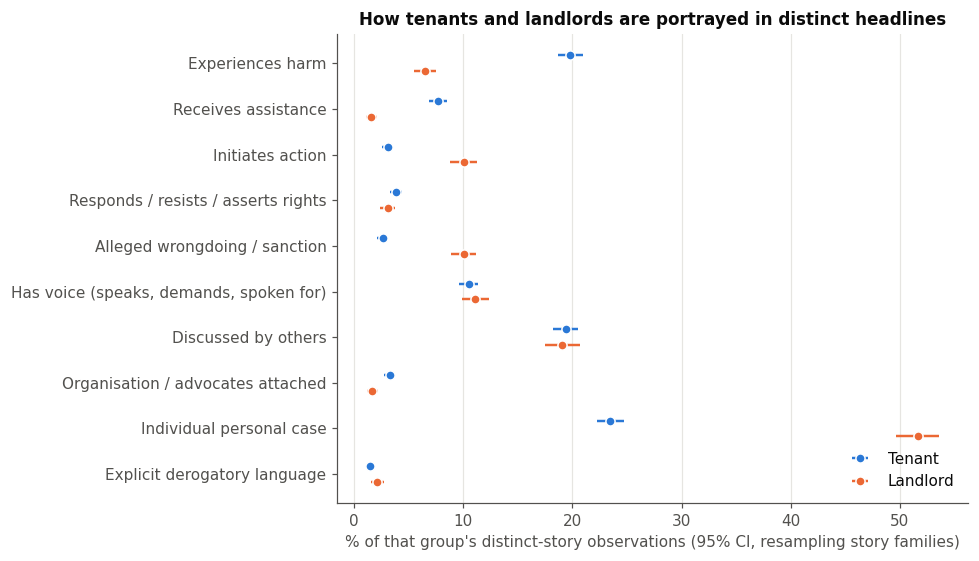

In [6]:
order = [o for o in ["harm_experienced", "assist_received", "act_initiate", "act_resist", "wrongdoing", "voice_any", "discussed_by_others", "const_org", "ind_individual", "derogatory_any"]]
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(order))[::-1]
for g, dy in [("tenant", 0.17), ("landlord", -0.17)]:
    vals = [overall.loc[o, f"rate_{g}"] * 100 for o in order]
    lo = [overall.loc[o, f"lo_{g}"] * 100 for o in order]
    hi = [overall.loc[o, f"hi_{g}"] * 100 for o in order]
    ax.errorbar(vals, y + dy, xerr=[np.array(vals) - lo, np.array(hi) - vals], fmt="o", color=COLORS[g], ms=6, lw=1.6, capsize=0, label=g.capitalize(), mec="white", mew=1)
ax.set_yticks(y)
ax.set_yticklabels([LABELS[o] for o in order])
ax.set_xlabel("% of that group's distinct-story observations (95% CI, resampling story families)")
ax.set_title("How tenants and landlords are portrayed in distinct headlines")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### Agency versus harm

Suffering and agency can coexist, so the figure below splits every observation into four mutually exclusive combinations: experiences harm only, acts only (initiates *or* resists), both, or neither. Raw counts come first; no victim-to-agent ratio is used because the denominator (agency) is small and the ratio is unstable.

% of observations                                         count                                    
                 Harm only Harm and action Action only Neither Harm only Harm and action Action only Neither
tenant                19.1             0.7         6.1    74.1       844              29         271    3267
landlord               6.0             0.5        12.1    81.4       141              11         284    1913

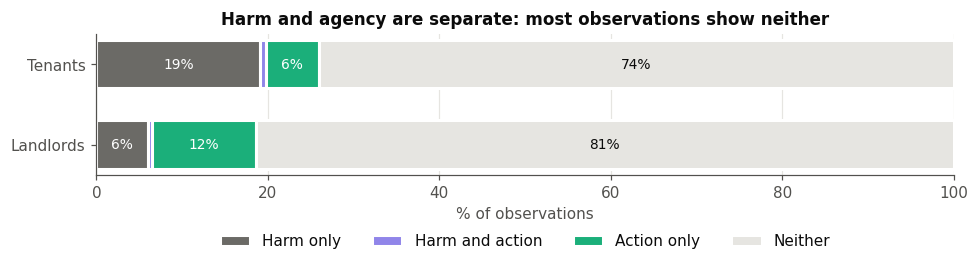

In [7]:
def combos(df):
    h, a = df["harm_experienced"], df["act_any"]
    return pd.Series({"Harm only": (h & ~a).mean(), "Harm and action": (h & a).mean(), "Action only": (~h & a).mean(), "Neither": (~h & ~a).mean()})


cmb = pd.DataFrame({g: combos(main[main["group"] == g]) for g in ["tenant", "landlord"]}).T * 100
cnt = pd.DataFrame({g: {"Harm only": int((main[main["group"] == g]["harm_experienced"] & ~main[main["group"] == g]["act_any"]).sum()),
                        "Harm and action": int((main[main["group"] == g]["harm_experienced"] & main[main["group"] == g]["act_any"]).sum()),
                        "Action only": int((~main[main["group"] == g]["harm_experienced"] & main[main["group"] == g]["act_any"]).sum()),
                        "Neither": int((~main[main["group"] == g]["harm_experienced"] & ~main[main["group"] == g]["act_any"]).sum())} for g in ["tenant", "landlord"]}).T
display(pd.concat({"% of observations": cmb.round(1), "count": cnt}, axis=1))

fig, ax = plt.subplots(figsize=(9, 2.8))
palette = {"Harm only": "#6b6a66", "Harm and action": "#9085e9", "Action only": "#1baf7a", "Neither": "#e6e5e1"}
left = np.zeros(2)
for c in ["Harm only", "Harm and action", "Action only", "Neither"]:
    vals = cmb[c].reindex(["tenant", "landlord"]).values
    ax.barh(["Tenants", "Landlords"][::-1], vals[::-1], left=left, color=palette[c], edgecolor="white", linewidth=2, height=0.6, label=c)
    for i, (v, l) in enumerate(zip(vals[::-1], left)):
        if v >= 4:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color=INK if c == "Neither" else "white", fontsize=9)
    left += vals[::-1]
ax.set_xlim(0, 100); ax.set_xlabel("% of observations")
ax.set_title("Harm and agency are separate: most observations show neither")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.32))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 4. Do the differences survive adjusting for outlet and year composition?

Tenant and landlord headlines come from somewhat different outlets and years (notebook 1 shows both are concentrated and uneven). The adjusted column asks: *if both groups were observed in the same mix of outlets and years, how large would the gap be?* Outlets enter as fixed effects, so the adjustment uses only within-outlet contrasts. Where the model is unreliable (few positives, thin overlap, unstable refits) the estimate is flagged and the transparent fallback below is used instead.

In [8]:
adj_rows = []
for o in tqdm(PRIMARY + ["responsibility"], desc="adjusted comparisons"):
    adj_rows.append({"outcome": o, **adj_diff(main, o)})
adjusted = pd.DataFrame(adj_rows).set_index("outcome")
cmp_tab = pd.DataFrame({
    "unadjusted pp (CI)": [f"{overall.loc[o, 'diff_pp']:+.1f} ({overall.loc[o, 'lo_pp']:+.1f} to {overall.loc[o, 'hi_pp']:+.1f})" for o in adjusted.index],
    "adjusted pp (CI)": [f"{adjusted.loc[o, 'adj_diff_pp']:+.1f} ({adjusted.loc[o, 'adj_lo_pp']:+.1f} to {adjusted.loc[o, 'adj_hi_pp']:+.1f})" for o in adjusted.index],
    "reliable": adjusted["adj_reliable"].values, "flags": adjusted["adj_flags"].values}, index=[LABELS[o] for o in adjusted.index])
display(cmp_tab)
diag = adjusted.iloc[0]
print(f"Model diagnostics: {int(diag.n_params)} parameters; common-support region = {diag.n_ref_sources} outlets covering {100 * diag.overlap_share:.0f}% of observations; "
      f"{100 * diag.sparse_cell_share:.0f}% of outlet×year cells in that region hold fewer than {SPARSE_CELL_N} observations (handled additively, so sparse cells are not estimated separately).")

adjusted comparisons:   0%|          | 0/11 [00:00<?, ?it/s]

,unadjusted pp (CI),adjusted pp (CI),reliable,flags
Experiences harm,+13.3 (+11.8 to +14.8),+13.5 (+12.1 to +15.2),True,
Initiates action,-7.0 (-8.2 to -5.6),-7.3 (-8.5 to -6.0),True,
Responds / resists / asserts rights,+0.8 (-0.1 to +1.7),+0.8 (-0.1 to +1.7),True,
Receives assistance,+6.1 (+5.1 to +7.1),+5.9 (+5.1 to +7.0),True,
"Has voice (speaks, demands, spoken for)",-0.6 (-2.2 to +0.9),-0.5 (-2.1 to +0.9),True,
Discussed by others,+0.3 (-1.5 to +2.2),+0.4 (-1.4 to +2.4),True,
Organisation / advocates attached,+1.6 (+0.9 to +2.3),+1.6 (+1.0 to +2.3),True,
Individual personal case,-28.2 (-30.4 to -25.8),-28.3 (-30.2 to -26.1),True,
Alleged wrongdoing / sanction,-7.4 (-8.7 to -6.1),-7.5 (-8.8 to -6.2),True,
Explicit derogatory language,-0.7 (-1.3 to -0.0),-0.5 (-1.2 to +0.1),True,


Model diagnostics: 39 parameters; common-support region = 22 outlets covering 91% of observations; 13% of outlet×year cells in that region hold fewer than 5 observations (handled additively, so sparse cells are not estimated separately).


**Fallback when adjustment is unreliable.** For any outcome flagged above, the transparent alternative is the *unadjusted* difference restricted to the common-support outlets only, shown here with its narrower scope.

In [9]:
sup_mask, sup_sources = common_support(main)
restricted = main[sup_mask]
fb = pd.DataFrame([{"outcome": LABELS[o], **{k: v for k, v in boot_diff(restricted, o, B=N_BOOT_ROBUST).items() if k in ("diff_pp", "lo_pp", "hi_pp", "n_tenant", "n_landlord")}}
                   for o in adjusted.index[~adjusted["adj_reliable"].values]])
print(f"Scope of the fallback: {len(sup_sources)} outlets with at least {MIN_PER_GROUP_SOURCE} observations of each group, {100 * sup_mask.mean():.0f}% of observations.")
display(fb.round(1).set_index("outcome") if len(fb) else pd.DataFrame({"note": ["all adjusted estimates passed the reliability checks"]}))

Scope of the fallback: 22 outlets with at least 15 observations of each group, 91% of observations.


,n_tenant,n_landlord,diff_pp,lo_pp,hi_pp
outcome,,,,,
Blamed / held responsible,4014,2138,-0.2,-0.5,0.1


## 5. Same headline, both groups

The cleanest comparison is within a headline that names *both* groups: the outlet, date, topic, length and wording are shared, so any difference is about how the two groups are described *in the same sentence*. The table counts the four possible patterns per outcome; the interval resamples headline families.

paired comparisons:   0%|          | 0/10 [00:00<?, ?it/s]

,pairs,tenant %,landlord %,both flagged,tenant only,landlord only,diff pp (95% CI)
outcome,,,,,,,
Experiences harm,821,17.3,7.4,27,115,34,+9.9 (+7.1 to +12.7)
Initiates action,821,2.2,10.2,5,13,79,-8.0 (-10.2 to -6.1)
Responds / resists / asserts rights,821,5.1,1.7,2,40,12,+3.4 (+1.7 to +5.2)
Receives assistance,821,3.8,1.2,5,26,5,+2.6 (+1.3 to +3.8)
"Has voice (speaks, demands, spoken for)",821,11.7,11.1,18,78,73,+0.6 (-2.1 to +3.3)
Discussed by others,821,10.2,11.2,46,38,46,-1.0 (-3.2 to +1.1)
Organisation / advocates attached,821,2.6,0.6,0,21,5,+1.9 (+0.7 to +3.3)
Individual personal case,821,32.9,59.3,225,45,262,-26.4 (-30.3 to -22.8)
Alleged wrongdoing / sanction,821,3.3,12.4,6,21,96,-9.1 (-11.6 to -6.7)


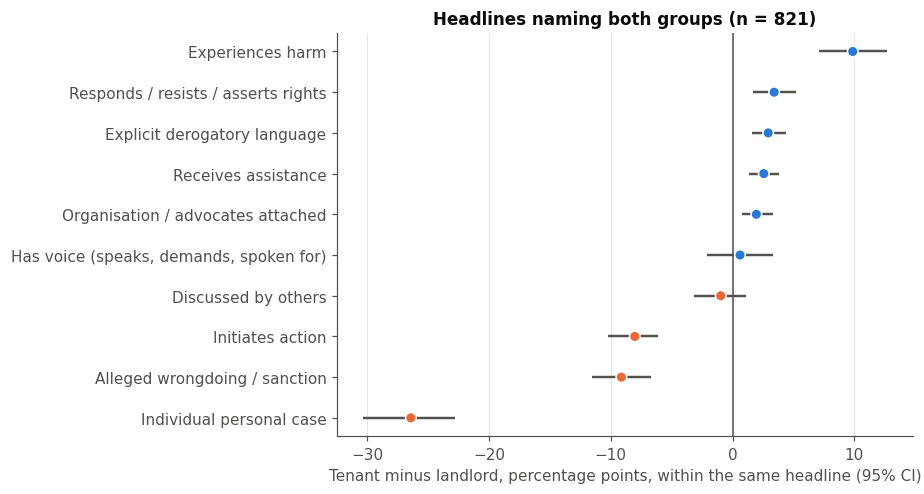

In [10]:
prow = []
for o in tqdm(PRIMARY, desc="paired comparisons"):
    prow.append({"outcome": o, **paired_diff(main, o)})
paired = pd.DataFrame(prow).set_index("outcome")
display(pd.DataFrame({
    "pairs": paired["n_pairs"], "tenant %": (100 * paired["rate_tenant"]).round(1), "landlord %": (100 * paired["rate_landlord"]).round(1),
    "both flagged": paired["both"], "tenant only": paired["tenant_only"], "landlord only": paired["landlord_only"],
    "diff pp (95% CI)": [f"{r.diff_pp:+.1f} ({r.lo_pp:+.1f} to {r.hi_pp:+.1f})" for r in paired.itertuples()]}).rename(index=LABELS))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
order_p = list(paired["diff_pp"].sort_values().index)
yy = np.arange(len(order_p))
ax.hlines(yy, [paired.loc[o, "lo_pp"] for o in order_p], [paired.loc[o, "hi_pp"] for o in order_p], color=MUTED, lw=1.6)
ax.scatter([paired.loc[o, "diff_pp"] for o in order_p], yy, color=[COLORS["tenant"] if paired.loc[o, "diff_pp"] > 0 else COLORS["landlord"] for o in order_p], s=48, zorder=3, edgecolor="white", linewidth=1)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(yy); ax.set_yticklabels([LABELS[o] for o in order_p])
ax.set_xlabel("Tenant minus landlord, percentage points, within the same headline (95% CI)")
ax.set_title(f"Headlines naming both groups (n = {int(paired['n_pairs'].iloc[0])})")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 6. What gets covered, and how, within the same topics

**Topic selection** is itself part of the framing difference (what a group is *in the news for*), so it is reported as an outcome. **Within-topic** comparisons then ask whether the groups are portrayed differently *when the story is about the same thing*. Adjusting for topic would hide the first part, so both are shown and neither replaces the overall result.

In [11]:
trows = []
for t in TOPICS:
    r = boot_diff(main, f"topic_{t}", B=N_BOOT_ROBUST)
    trows.append({"topic": t, "tenant %": 100 * r["rate_tenant"], "landlord %": 100 * r["rate_landlord"], "diff pp": r["diff_pp"], "lo": r["lo_pp"], "hi": r["hi_pp"],
                  "n obs tenant": r["n_tenant"], "n obs landlord": r["n_landlord"]})
topic_sel = pd.DataFrame(trows).set_index("topic")
display(topic_sel.round(1))

within_rows = []
for t in WITHIN_TOPIC:
    sub = main[main[f"topic_{t}"]]
    for o in PRIMARY:
        r = boot_diff(sub, o, B=N_BOOT_ROBUST)
        within_rows.append({"topic": t, "outcome": o, **r})
within = pd.DataFrame(within_rows)
print("Within-topic differences (tenant − landlord, pp). n shown in parentheses:")
w_tab = within.assign(cell=lambda d: [f"{r.diff_pp:+.1f} ({r.lo_pp:+.1f}…{r.hi_pp:+.1f})  n={r.n_tenant}/{r.n_landlord}" for r in d.itertuples()]).pivot(index="outcome", columns="topic", values="cell")
display(w_tab.rename(index=LABELS).reindex([LABELS[o] for o in PRIMARY]))

,tenant %,landlord %,diff pp,lo,hi,n obs tenant,n obs landlord
topic,,,,,,,
eviction,18.5,12.8,5.8,4.5,7.1,4411,2349
affordability,8.4,5.4,3.0,2.0,4.0,4411,2349
conditions,19.5,11.6,8.0,6.4,9.5,4411,2349
dispute,15.5,26.6,-11.1,-13.0,-9.3,4411,2349
regulation,12.6,14.5,-2.0,-3.4,-0.5,4411,2349
organizing,7.2,5.6,1.7,0.6,2.7,4411,2349
investment,9.7,8.8,0.8,-0.4,2.1,4411,2349
crime,7.6,14.5,-6.8,-8.1,-5.4,4411,2349


Within-topic differences (tenant − landlord, pp). n shown in parentheses:


topic,dispute,eviction
outcome,,
Experiences harm,+9.5 (+6.6…+13.2) n=683/625,+42.6 (+38.3…+47.4) n=817/300
Initiates action,-5.3 (-7.4…-3.3) n=683/625,-19.6 (-24.2…-14.8) n=817/300
Responds / resists / asserts rights,+8.1 (+5.0…+11.5) n=683/625,+2.8 (-0.4…+5.5) n=817/300
Receives assistance,+2.3 (+1.0…+3.8) n=683/625,+6.8 (+4.6…+9.3) n=817/300
"Has voice (speaks, demands, spoken for)",+2.3 (-0.6…+5.3) n=683/625,-0.1 (-4.2…+4.8) n=817/300
Discussed by others,-5.0 (-8.9…-1.3) n=683/625,-3.1 (-8.1…+1.7) n=817/300
Organisation / advocates attached,+1.5 (+0.2…+2.9) n=683/625,+1.7 (-0.7…+3.7) n=817/300
Individual personal case,-31.4 (-36.2…-26.5) n=683/625,-45.7 (-51.5…-40.8) n=817/300
Alleged wrongdoing / sanction,-17.1 (-21.5…-13.2) n=683/625,-7.3 (-10.3…-4.1) n=817/300


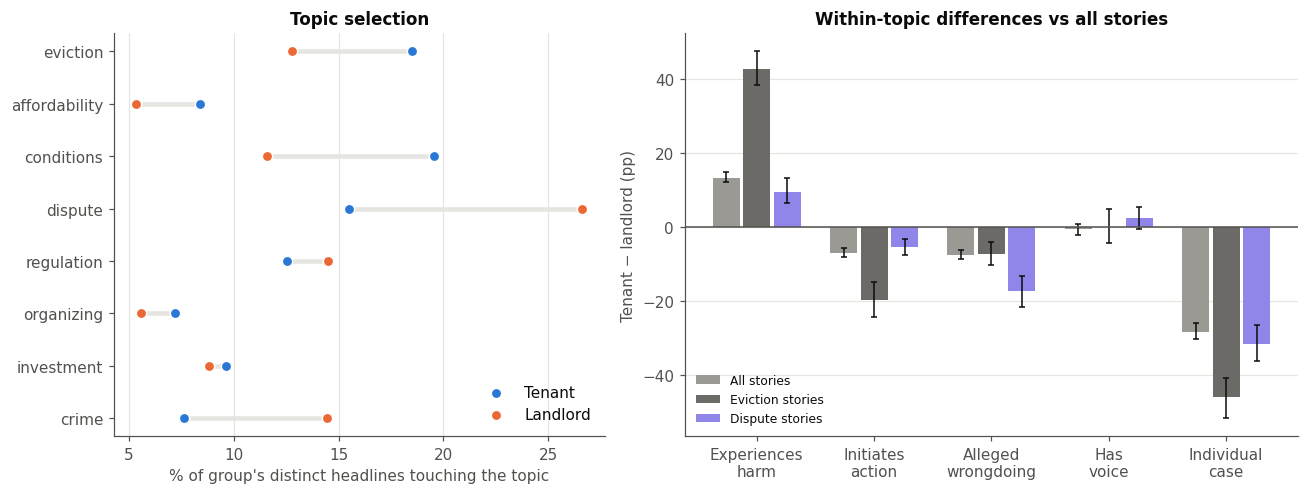

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
yy = np.arange(len(TOPICS))[::-1]
ts = topic_sel.reindex(TOPICS)
ax.hlines(yy, ts["tenant %"], ts["landlord %"], color=GRID, lw=3, zorder=1)
ax.scatter(ts["tenant %"], yy, color=COLORS["tenant"], s=46, zorder=3, label="Tenant", edgecolor="white", linewidth=1)
ax.scatter(ts["landlord %"], yy, color=COLORS["landlord"], s=46, zorder=3, label="Landlord", edgecolor="white", linewidth=1)
ax.set_yticks(yy); ax.set_yticklabels(TOPICS); ax.set_xlabel("% of group's distinct headlines touching the topic")
ax.set_title("Topic selection"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax = axes[1]
base_o = ["harm_experienced", "act_initiate", "wrongdoing", "voice_any", "ind_individual"]
x0 = np.arange(len(base_o))
width = 0.26
for j, (name, d) in enumerate([("All stories", pd.DataFrame([{**boot_diff(main, o, B=N_BOOT_ROBUST), "outcome": o} for o in base_o]).set_index("outcome")),
                               ("Eviction stories", within[within["topic"] == "eviction"].set_index("outcome").loc[base_o]),
                               ("Dispute stories", within[within["topic"] == "dispute"].set_index("outcome").loc[base_o])]):
    ax.bar(x0 + (j - 1) * width, d["diff_pp"].values, width=width - 0.03, color=["#9a9994", "#6b6a66", "#9085e9"][j], label=name)
    ax.errorbar(x0 + (j - 1) * width, d["diff_pp"].values, yerr=[d["diff_pp"].values - d["lo_pp"].values, d["hi_pp"].values - d["diff_pp"].values], fmt="none", ecolor=INK, elinewidth=1, capsize=2)
ax.axhline(0, color=MUTED, lw=1)
SHORT = {"harm_experienced": "Experiences\nharm", "act_initiate": "Initiates\naction", "wrongdoing": "Alleged\nwrongdoing", "voice_any": "Has\nvoice", "ind_individual": "Individual\ncase"}
ax.set_xticks(x0); ax.set_xticklabels([SHORT[o] for o in base_o])
ax.set_ylabel("Tenant − landlord (pp)"); ax.set_title("Within-topic differences vs all stories"); ax.legend(loc="lower left", fontsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Topic adjustment, shown beside (not instead of) the overall result.** The next table adds topic indicators to the outlet+year model.

In [13]:
topic_adj = {}
for o in tqdm(PRIMARY, desc="topic-adjusted"):
    topic_adj[o] = adj_diff(main, o, extra=topic_cols, B=N_BOOT_ADJ)
ta = pd.DataFrame({
    "unadjusted": [f"{overall.loc[o, 'diff_pp']:+.1f}" for o in PRIMARY],
    "outlet+year adjusted": [f"{adjusted.loc[o, 'adj_diff_pp']:+.1f} ({adjusted.loc[o, 'adj_lo_pp']:+.1f} to {adjusted.loc[o, 'adj_hi_pp']:+.1f})" for o in PRIMARY],
    "outlet+year+topic adjusted": [f"{topic_adj[o]['adj_diff_pp']:+.1f} ({topic_adj[o]['adj_lo_pp']:+.1f} to {topic_adj[o]['adj_hi_pp']:+.1f})" for o in PRIMARY]}, index=[LABELS[o] for o in PRIMARY])
display(ta)

topic-adjusted:   0%|          | 0/10 [00:00<?, ?it/s]

,unadjusted,outlet+year adjusted,outlet+year+topic adjusted
Experiences harm,+13.3,+13.5 (+12.1 to +15.2),+11.9 (+10.5 to +13.6)
Initiates action,-7.0,-7.3 (-8.5 to -6.0),-7.9 (-9.2 to -6.5)
Responds / resists / asserts rights,+0.8,+0.8 (-0.1 to +1.7),+1.1 (+0.3 to +2.0)
Receives assistance,+6.1,+5.9 (+5.1 to +7.0),+5.8 (+4.9 to +6.7)
"Has voice (speaks, demands, spoken for)",-0.6,-0.5 (-2.1 to +0.9),-1.1 (-2.8 to +0.4)
Discussed by others,+0.3,+0.4 (-1.4 to +2.4),+0.7 (-1.0 to +2.7)
Organisation / advocates attached,+1.6,+1.6 (+1.0 to +2.3),+1.2 (+0.6 to +2.0)
Individual personal case,-28.2,-28.3 (-30.2 to -26.1),-24.6 (-26.7 to -22.3)
Alleged wrongdoing / sanction,-7.4,-7.5 (-8.8 to -6.2),-5.7 (-6.8 to -4.6)
Explicit derogatory language,-0.7,-0.5 (-1.2 to +0.1),-0.3 (-1.0 to +0.2)


## 7. Annual patterns

Years are shown for a group only when it has at least `MIN_N_YEAR` observations. The pandemic-era look is *descriptive*: no year is assumed to be a turning point, and a change over time is not interpreted as caused by anything. Indexing also changes across years (notebook 1), so year-to-year movement mixes real shifts in coverage with changes in which outlets are indexed.

Years with at least 40 observations for both groups: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


,year,n_tenant,n_landlord,rate_tenant,rate_landlord,diff_pp,lo_pp,hi_pp,shown
0,2015,224,145,0.161,0.041,11.933,5.688,17.293,True
1,2016,268,168,0.146,0.071,7.409,1.659,12.989,True
2,2017,435,221,0.189,0.086,10.253,5.168,15.108,True
3,2018,468,276,0.214,0.047,16.657,12.192,21.838,True
4,2019,511,238,0.270,0.059,21.124,16.317,25.632,True
5,2020,586,404,0.200,0.062,13.778,9.940,17.351,True
6,2021,389,180,0.136,0.067,6.958,1.625,12.327,True
7,2022,399,157,0.218,0.057,16.072,10.874,20.813,True
8,2023,380,173,0.242,0.087,15.540,9.607,21.260,True
9,2024,472,213,0.153,0.070,8.212,3.459,12.562,True


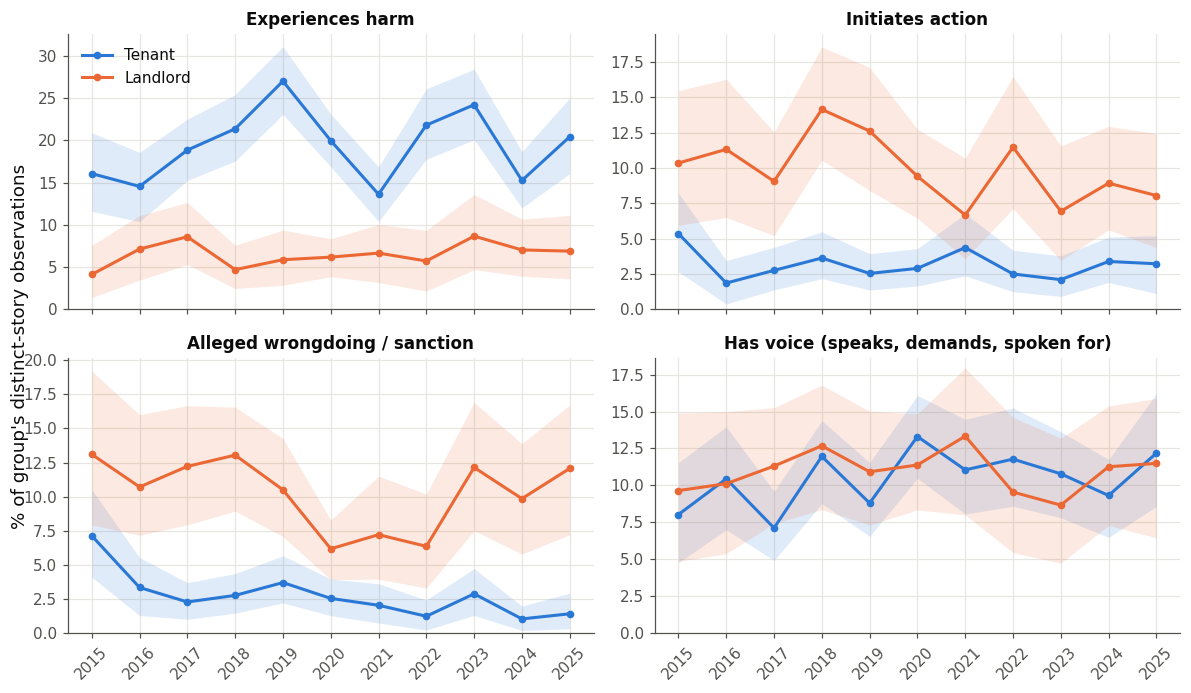

In [14]:
TREND = ["harm_experienced", "act_initiate", "wrongdoing", "voice_any"]
yr_rows = []
for o in TREND:
    for yv in sorted(main["year"].unique()):
        sub = main[main["year"] == yv]
        r = boot_diff(sub, o, B=N_BOOT_ROBUST)
        yr_rows.append({"outcome": o, "year": int(yv), **r})
by_year = pd.DataFrame(yr_rows)
by_year["shown"] = (by_year["n_tenant"] >= MIN_N_YEAR) & (by_year["n_landlord"] >= MIN_N_YEAR)
print(f"Years with at least {MIN_N_YEAR} observations for both groups: {sorted(by_year[by_year['shown']]['year'].unique().tolist())}")
display(by_year[by_year["outcome"] == "harm_experienced"][["year", "n_tenant", "n_landlord", "rate_tenant", "rate_landlord", "diff_pp", "lo_pp", "hi_pp", "shown"]].round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True)
for ax, o in zip(axes.ravel(), TREND):
    d = by_year[(by_year["outcome"] == o) & by_year["shown"]]
    for g in ["tenant", "landlord"]:
        ax.plot(d["year"], 100 * d[f"rate_{g}"], color=COLORS[g], lw=2, marker="o", ms=4, label=g.capitalize())
        ax.fill_between(d["year"], 100 * d[f"lo_{g}"], 100 * d[f"hi_{g}"], color=COLORS[g], alpha=0.14, lw=0)
    ax.set_title(LABELS[o]); ax.set_ylim(bottom=0); ax.set_xticks(sorted(d["year"].unique()))
    ax.tick_params(axis="x", rotation=45)
axes[0, 0].legend(loc="upper left")
fig.supylabel("% of group's distinct-story observations")
plt.tight_layout(); plt.show()

In [15]:
per_rows = []
for o in TREND:
    for name, (a, b) in PERIODS.items():
        sub = main[main["year"].between(a, b)]
        r = boot_diff(sub, o, B=N_BOOT_ROBUST)
        per_rows.append({"outcome": LABELS[o], "period": name, "tenant %": round(100 * r["rate_tenant"], 1), "landlord %": round(100 * r["rate_landlord"], 1),
                         "gap pp (CI)": f"{r['diff_pp']:+.1f} ({r['lo_pp']:+.1f} to {r['hi_pp']:+.1f})", "n (t/l)": f"{r['n_tenant']}/{r['n_landlord']}"})
display(pd.DataFrame(per_rows).set_index(["outcome", "period"]))
h = by_year[(by_year["outcome"] == "harm_experienced") & by_year["shown"]].set_index("year")
if 2020 in h.index and len(h) > 3:
    others = h.drop(index=2020)
    inside = others["lo_pp"].min() <= h.loc[2020, "diff_pp"] <= others["hi_pp"].max()
    print(f"Tenant−landlord harm gap in 2020: {h.loc[2020, 'diff_pp']:+.1f} pp; other years range {others['diff_pp'].min():+.1f} to {others['diff_pp'].max():+.1f} pp. "
          f"2020 {'is within the spread of other years (so no special turning point is evident)' if inside else 'lies outside the spread of other years; this is descriptive only'}.")

tenant %  landlord %             gap pp (CI)    n (t/l)
outcome                                 period                                                            
Experiences harm                        2015–2019      20.7         6.1  +14.6 (+12.4 to +17.2)  1906/1048
                                        2020–2021      17.4         6.3   +11.1 (+7.7 to +13.7)    975/584
                                        2022–2025      20.1         7.1  +13.0 (+10.4 to +15.6)   1530/717
Initiates action                        2015–2019       3.1        11.7    -8.6 (-10.9 to -6.5)  1906/1048
                                        2020–2021       3.5         8.6     -5.1 (-7.6 to -2.9)    975/584
                                        2022–2025       2.8         8.8     -6.0 (-8.7 to -3.7)   1530/717
Alleged wrongdoing / sanction           2015–2019       3.5        11.9    -8.4 (-10.5 to -6.4)  1906/1048
                                        2020–2021       2.4         6.5     -4.1 (-6.0 to -2.1)    975/584
                                        2022–2025       1.6        10.2    -8.5 (-11.0 to -6.6)   1530/717
Has voice (speaks, demands, spoken for) 2015–2019       9.3        11.2     -1.8 (-4.0 to +0.5)  1906/1048
                                        2020–2021      12.4        12.0     +0.4 (-2.8 to +3.9)    975/584
                                        2022–2025      10.8        10.3     +0.5 (-1.7 to +3.1)   1530/717

Tenant−landlord harm gap in 2020: +13.8 pp; other years range +7.0 to +21.1 pp. 2020 is within the spread of other years (so no special turning point is evident).


## 8. Coverage frequency (kept separate from framing)

*How often are tenants and landlords mentioned relative to everything an outlet published, as indexed?* This needs (a) **publication-copy numerators**, i.e. every copy a given outlet ran, not the hierarchy-selected representatives, and (b) **indexed-volume denominators** from the same outlet-years. Hierarchy-deduplicated counts are never used as numerators. Only outlet-years with stable coverage (enough indexed volume, no abrupt break) and outlets stable in most years are used, and the rate is per 10,000 indexed stories. Rates are *not* comparable across outlets that index different slices of their output, so only the pooled trend is shown.

9 stable outlets; 89 stable outlet-years; 3,575 tenant/landlord mention-copies in 3,354,470 indexed stories.


,year,outlets,indexed_stories,tenant_per10k,tenant_lo,tenant_hi,landlord_per10k,landlord_lo,landlord_hi
0,2015,5,142812,6.86,4.90,7.35,3.36,1.93,3.95
1,2016,7,156299,5.57,4.21,6.26,3.97,2.36,5.57
2,2017,6,190292,8.51,5.36,10.66,3.63,2.15,4.52
3,2018,9,301303,6.80,2.80,10.25,3.98,1.57,6.06
4,2019,9,391626,6.31,3.37,8.64,2.89,1.26,3.96
5,2020,9,415602,8.69,4.14,11.00,6.06,2.86,8.11
6,2021,9,446751,5.22,2.54,6.90,2.28,0.77,2.88
7,2022,9,380620,6.73,2.46,9.85,3.00,1.16,4.28
8,2023,9,339206,8.79,3.92,12.01,3.69,1.72,5.06
9,2024,9,345181,9.07,3.66,13.65,3.62,1.62,5.01


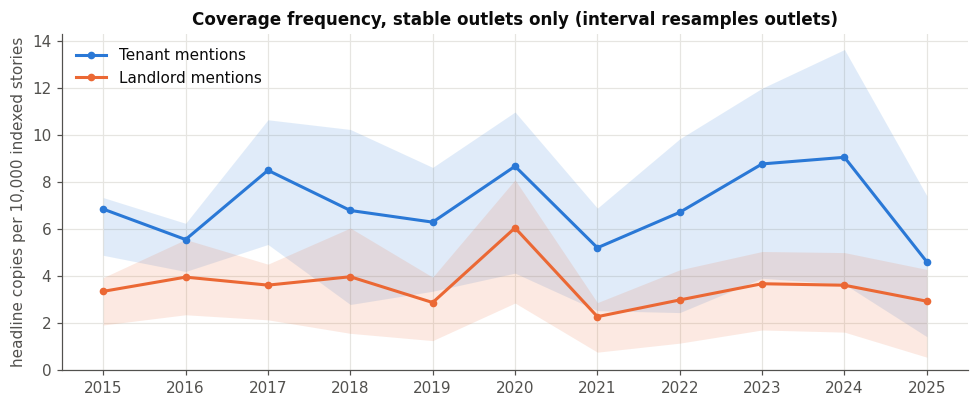

In [16]:
if not HAS_COPIES:
    print("Original publication copies are not available: coverage-frequency rates cannot be computed and are skipped.")
    freq = pd.DataFrame()
else:
    cov = pd.read_csv(COVERAGE_PATH)
    pv = cov.pivot_table(index="source", columns="year", values="matching_stories", aggfunc="sum").fillna(0)
    flag = pd.DataFrame(index=pv.index, columns=pv.columns, dtype=object)
    for src in pv.index:
        for yv in pv.columns:
            v, prev = pv.loc[src, yv], pv.loc[src, yv - 1] if (yv - 1) in pv.columns else np.nan
            flag.loc[src, yv] = "ok" if (v >= MIN_INDEXED_STABLE and not (prev >= JUMP_MIN_BASE and (v >= JUMP_FACTOR * prev or v * JUMP_FACTOR <= prev))) else "unstable"
    stable_sources = flag.index[(flag == "ok").sum(axis=1) >= STABLE_MIN_OK_YEARS]
    ok_cells = {(s, y) for s in stable_sources for y in flag.columns if flag.loc[s, y] == "ok"}
    pub = prepared[prepared["mention_group"].isin(["tenant", "landlord", "both"])]
    pub = pub[[(s, y) in ok_cells for s, y in zip(pub["media_name"], pub["year"])]]
    num = pd.DataFrame({"tenant": pub["mention_group"].isin(["tenant", "both"]), "landlord": pub["mention_group"].isin(["landlord", "both"]), "source": pub["media_name"], "year": pub["year"]})
    panel = pd.DataFrame([(s, y, pv.loc[s, y]) for (s, y) in sorted(ok_cells)], columns=["source", "year", "indexed"])
    panel = panel.merge(num.groupby(["source", "year"])[["tenant", "landlord"]].sum().reset_index(), on=["source", "year"], how="left").fillna(0)
    assert (panel["tenant"] <= panel["indexed"]).all() and (panel["landlord"] <= panel["indexed"]).all(), "numerators must not exceed indexed denominators"
    rng = np.random.default_rng(SEED)
    srcs = panel["source"].unique()
    rows = []
    for yv, d in panel.groupby("year"):
        rec = {"year": yv, "outlets": d["source"].nunique(), "indexed_stories": int(d["indexed"].sum())}
        by_src = d.groupby("source")[["tenant", "landlord", "indexed"]].sum()
        idx = rng.integers(0, len(by_src), size=(300, len(by_src)))
        for g in ["tenant", "landlord"]:
            rec[f"{g}_per10k"] = RATE_PER * by_src[g].sum() / by_src["indexed"].sum()
            draws = RATE_PER * by_src[g].values[idx].sum(1) / by_src["indexed"].values[idx].sum(1)
            rec[f"{g}_lo"], rec[f"{g}_hi"] = _ci(draws)
        rows.append(rec)
    freq = pd.DataFrame(rows)
    print(f"{len(stable_sources)} stable outlets; {len(ok_cells)} stable outlet-years; {int(panel['tenant'].sum() + panel['landlord'].sum()):,} tenant/landlord mention-copies "
          f"in {int(panel['indexed'].sum()):,} indexed stories.")
    display(freq.round(2))
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for g in ["tenant", "landlord"]:
        ax.plot(freq["year"], freq[f"{g}_per10k"], color=COLORS[g], lw=2, marker="o", ms=4, label=f"{g.capitalize()} mentions")
        ax.fill_between(freq["year"], freq[f"{g}_lo"], freq[f"{g}_hi"], color=COLORS[g], alpha=0.14, lw=0)
    ax.set_ylim(bottom=0); ax.set_xticks(freq["year"]); ax.set_ylabel(f"headline copies per {RATE_PER:,} indexed stories")
    ax.set_title("Coverage frequency, stable outlets only (interval resamples outlets)")
    ax.legend(loc="upper left")
    plt.tight_layout(); plt.show()

Coverage frequency can rise or fall for reasons unrelated to framing (what the outlet publishes, which sections are indexed), so it is *not* used to infer how the groups are portrayed. A tenants-versus-landlords gap in frequency is also partly an artifact of the search words used to build the corpus: "tenant/renter" and "landlord" are different words with different base rates in news writing.

## 9. Robustness grid

Each check re-estimates the tenant − landlord difference for the headline outcomes:

1. **Main** — distinct near-duplicate story families, unadjusted
2. **Exact families** — identical-title matching only (more copies of syndicated stories survive)
3. **Outlet+year adjusted**
4. **Stable-coverage outlets** — only outlet-years with stable indexed volume
5. **Leave-one-outlet-out** for each of the largest outlets
6. **Residential only** (drops commercial and mixed-cue headlines) and **strict residential** (explicit residential cues only)
7. **Shared headlines** (paired) and **within-topic** (eviction, dispute) comparisons
8. **Topic-adjusted** (shown beside, not instead of, the overall result)
9. **All publication copies** (outlet view; syndicated stories weigh more)
10. **Alternative coding definitions** of the outcome (stricter or broader)

In [17]:
if HAS_COPIES:
    stable_mask = [(s, y) in ok_cells for s, y in zip(main["media_name"], main["year"])]
else:
    stable_mask = [False] * len(main)
top_outlets = main["media_name"].value_counts().head(DOMINANT_K).index.tolist()
ALT = {"harm_experienced": ("harm_event", "harm: events only (no adjectives/nouns)"), "act_initiate": ("act_any", "agency: initiate OR resist"),
       "voice_any": ("voice_speaks_only", "voice: speaking only"), "const_org": ("const_any", "constituency: org OR collective OR policy"),
       "wrongdoing": ("wrongdoing_unhedged", "wrongdoing: excluding hedged/alleged"), "derogatory_any": ("derogatory", "derogatory: excluding quoted"),
       "ind_individual": ("ind_singular_only", "individual: singular term only")}
rows = []


def add(spec, o, r, kind="unadjusted", note=""):
    d = {"analysis": kind, "spec": spec, "outcome": o, "rate_tenant": r.get("rate_tenant", r.get("adj_rate_tenant", np.nan)), "rate_landlord": r.get("rate_landlord", r.get("adj_rate_landlord", np.nan)),
         "diff_pp": r.get("diff_pp", r.get("adj_diff_pp", np.nan)), "lo_pp": r.get("lo_pp", r.get("adj_lo_pp", np.nan)), "hi_pp": r.get("hi_pp", r.get("adj_hi_pp", np.nan)),
         "n_tenant": r.get("n_tenant", np.nan), "n_landlord": r.get("n_landlord", np.nan), "n_families": r.get("n_families", r.get("n_pairs", np.nan)), "reliable": r.get("adj_reliable", True), "note": note}
    rows.append(d)


specs = [("main", main, N_BOOT), ("exact families", exact, N_BOOT_ROBUST), ("stable-coverage outlets", main[stable_mask], N_BOOT_ROBUST),
         ("residential only", main[main["relevance"].isin(["residential", "unclear"])], N_BOOT_ROBUST), ("strict residential", main[main["relevance"] == "residential"], N_BOOT_ROBUST),
         ("all publication copies", copies, N_BOOT_ROBUST)]
specs += [(f"drop {s}", main[main["media_name"] != s], N_BOOT_ROBUST) for s in top_outlets]
for o in tqdm(PRIMARY, desc="robustness grid"):
    for name, d, B in specs:
        if len(d) == 0:
            continue
        add(name, o, boot_diff(d, o, B=B))
    add("outlet+year adjusted", o, adjusted.loc[o].to_dict(), "adjusted", adjusted.loc[o, "adj_flags"])
    add("outlet+year+topic adjusted", o, topic_adj[o], "adjusted", topic_adj[o]["adj_flags"])
    sa = adj_diff(main[stable_mask], o, B=N_BOOT_ADJ) if sum(stable_mask) else None
    if sa:
        add("stable outlets, adjusted", o, sa, "adjusted", sa["adj_flags"])
    add("shared headlines (paired)", o, paired.loc[o].to_dict() | {"n_families": paired.loc[o, "n_pairs"]}, "paired")
    for t in WITHIN_TOPIC:
        add(f"within topic: {t}", o, within[(within["topic"] == t) & (within["outcome"] == o)].iloc[0].to_dict(), "within-topic")
    if o in ALT:
        add(f"alt coding: {ALT[o][1]}", o, boot_diff(main, ALT[o][0], B=N_BOOT_ROBUST), "alternative definition")
grid = pd.DataFrame(rows)
print(f"{len(grid)} estimates across {grid['spec'].nunique()} specifications for {grid['outcome'].nunique()} outcomes")

robustness grid:   0%|          | 0/10 [00:00<?, ?it/s]

177 estimates across 24 specifications for 10 outcomes


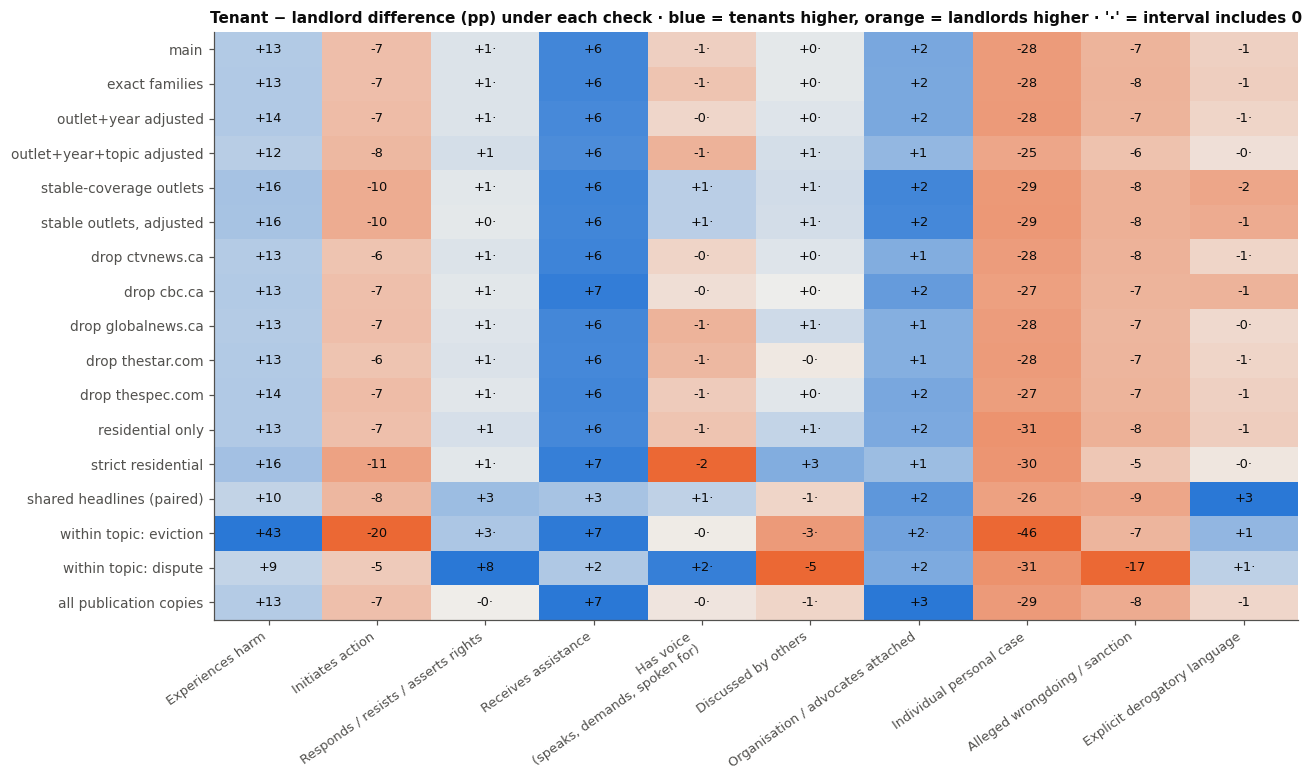

In [18]:
spec_order = ["main", "exact families", "outlet+year adjusted", "outlet+year+topic adjusted", "stable-coverage outlets", "stable outlets, adjusted"] + [f"drop {s}" for s in top_outlets] + \
             ["residential only", "strict residential", "shared headlines (paired)", "within topic: eviction", "within topic: dispute", "all publication copies"]
H = grid[grid["spec"].isin(spec_order)].pivot(index="spec", columns="outcome", values="diff_pp").reindex(spec_order)[PRIMARY]
SIG = grid[grid["spec"].isin(spec_order)].assign(sig=lambda d: (d["lo_pp"] > 0) | (d["hi_pp"] < 0)).pivot(index="spec", columns="outcome", values="sig").reindex(spec_order)[PRIMARY]
fig, ax = plt.subplots(figsize=(12, 7.2))
scale = H.abs().max()
im = ax.imshow((H / scale).values, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:+.0f}" + ("" if SIG.iat[i, j] else "·"), ha="center", va="center", fontsize=8.5, color=INK)
ax.set_xticks(range(len(PRIMARY))); ax.set_xticklabels([LABELS[o].replace(" (", "\n(") for o in PRIMARY], rotation=35, ha="right", fontsize=8.5)
ax.set_yticks(range(len(spec_order))); ax.set_yticklabels(spec_order, fontsize=9)
ax.grid(False)
ax.set_title("Tenant − landlord difference (pp) under each check · blue = tenants higher, orange = landlords higher · '·' = interval includes 0", fontsize=10)
plt.tight_layout(); plt.show()

In [19]:
alt = grid[grid["analysis"] == "alternative definition"].copy()
alt["main definition"] = alt["outcome"].map(LABELS)
alt["main diff pp"] = alt["outcome"].map(overall["diff_pp"]).round(1)
alt["alternative diff pp (CI)"] = [f"{r.diff_pp:+.1f} ({r.lo_pp:+.1f} to {r.hi_pp:+.1f})" for r in alt.itertuples()]
print("Alternative coding definitions of the main outcomes:")
display(alt[["main definition", "spec", "main diff pp", "alternative diff pp (CI)"]].rename(columns={"spec": "alternative definition"}).set_index("main definition"))


def agreement(outcome):
    g = grid[(grid["outcome"] == outcome) & (grid["spec"] != "main") & grid["reliable"] & grid["diff_pp"].notna() & (grid["analysis"] != "alternative definition")]
    m = grid[(grid["outcome"] == outcome) & (grid["spec"] == "main")].iloc[0]
    same = np.sign(g["diff_pp"]) == np.sign(m["diff_pp"])
    sigd = same & ((g["lo_pp"] > 0) | (g["hi_pp"] < 0))
    return pd.Series({"main diff pp": m["diff_pp"], "checks": len(g), "same sign": float(same.mean()) if len(g) else np.nan, "same sign & CI excludes 0": float(sigd.mean()) if len(g) else np.nan,
                      "min diff": g["diff_pp"].min(), "max diff": g["diff_pp"].max()})


consistency = pd.DataFrame({o: agreement(o) for o in PRIMARY}).T
display(consistency.rename(index=LABELS).round(2))

Alternative coding definitions of the main outcomes:


,alternative definition,main diff pp,alternative diff pp (CI)
main definition,,,
Experiences harm,alt coding: harm: events only (no adjectives/nouns),13.3,+9.5 (+8.3 to +10.8)
Initiates action,alt coding: agency: initiate OR resist,-7.0,-5.8 (-7.1 to -4.4)
"Has voice (speaks, demands, spoken for)",alt coding: voice: speaking only,-0.6,-0.2 (-1.6 to +0.9)
Organisation / advocates attached,alt coding: constituency: org OR collective OR policy,1.6,+2.3 (+1.4 to +3.1)
Individual personal case,alt coding: individual: singular term only,-28.2,-29.0 (-31.0 to -26.7)
Alleged wrongdoing / sanction,alt coding: wrongdoing: excluding hedged/alleged,-7.4,-4.3 (-5.4 to -3.2)
Explicit derogatory language,alt coding: derogatory: excluding quoted,-0.7,-0.5 (-1.0 to +0.0)


,main diff pp,checks,same sign,same sign & CI excludes 0,min diff,max diff
Experiences harm,13.32,16.0,1.00,1.00,9.46,42.64
Initiates action,-6.96,16.0,1.00,1.00,-19.64,-5.27
Responds / resists / asserts rights,0.77,16.0,0.94,0.25,-0.11,8.14
Receives assistance,6.11,16.0,1.00,1.00,2.30,7.02
"Has voice (speaks, demands, spoken for)",-0.57,16.0,0.75,0.06,-2.47,2.32
Discussed by others,0.31,16.0,0.69,0.06,-5.03,2.76
Organisation / advocates attached,1.60,16.0,1.00,0.94,1.13,2.68
Individual personal case,-28.20,16.0,1.00,1.00,-45.73,-24.60
Alleged wrongdoing / sanction,-7.44,16.0,1.00,1.00,-17.13,-5.02
Explicit derogatory language,-0.66,16.0,0.81,0.44,-1.56,2.92


## 10. Validation status of the measures

If the review file in notebook 2 has been completed, precision on the random validation sample decides whether a measure may be called *supported*. If not, **no measure is validated**, and every finding stays at best *provisional*.

In [20]:
YES, NO = {"1", "Y", "YES", "TRUE", "T"}, {"0", "N", "NO", "FALSE", "F"}
REVIEW_TO_PRED = {"individual": "ind_individual", "derogatory": "derogatory_any"}
PRED_TO_REVIEW = {"ind_individual": "individual", "derogatory_any": "derogatory"}


def validation_status():
    """Per outcome: 'validated', 'unreliable', 'too few labelled positives', or 'not reviewed'."""
    if not Path(REVIEW_LABELS_PATH).exists():
        return {o: "not reviewed" for o in PRIMARY}
    df = pd.read_csv(REVIEW_LABELS_PATH, dtype=str, keep_default_na=False)
    lab_cols = [c for c in df.columns if c.startswith("h_") and c not in ("h_notes",) and not c.startswith("h_topic_")]
    if not (df[lab_cols].apply(lambda s: s.str.strip().str.upper()).isin(YES | NO)).any().any():
        return {o: "not reviewed" for o in PRIMARY}
    df = df[(df["phase"] == "validation") & (df["meta_component"] == "validation_random")]
    ann = annotations.set_index(["id", "group"])
    status = {}
    for o in PRIMARY:
        d = PRED_TO_REVIEW.get(o, o)
        y_all, p_all = [], []
        for r in df.itertuples():
            for g in ["tenant", "landlord"]:
                v = str(getattr(r, f"h_{g}_{d}", "")).strip().upper()
                if v in YES | NO and (r.id, g) in ann.index:
                    y_all.append(v in YES); p_all.append(bool(ann.at[(r.id, g), o]))
        y_all, p_all = np.array(y_all, bool), np.array(p_all, bool)
        if y_all.sum() < MIN_POSITIVES or p_all.sum() < MIN_POSITIVES:
            status[o] = "too few labelled positives"
            continue
        prec = (y_all & p_all).sum() / p_all.sum()
        status[o] = "validated" if prec >= LOW_PRECISION else "unreliable"
    return status


VALIDATION = validation_status()
display(pd.Series(VALIDATION, name="validation status").rename(index=LABELS).to_frame())
if all(v == "not reviewed" for v in VALIDATION.values()):
    print("No completed review labels were found: nothing is validated, so no finding below can be labelled 'Supported'.")

,validation status
Experiences harm,not reviewed
Initiates action,not reviewed
Responds / resists / asserts rights,not reviewed
Receives assistance,not reviewed
"Has voice (speaks, demands, spoken for)",not reviewed
Discussed by others,not reviewed
Organisation / advocates attached,not reviewed
Individual personal case,not reviewed
Alleged wrongdoing / sanction,not reviewed
Explicit derogatory language,not reviewed


No completed review labels were found: nothing is validated, so no finding below can be labelled 'Supported'.


## 11. Synthesis

Everything below is generated from the results above.

In [21]:
CAVEATS = {"ind_individual": "partly an artifact of singular/plural wording (see alternative definition)", "harm_experienced": "includes fires and crime incidents",
           "wrongdoing": "includes crime reports; sanction language is hedged by definition", "derogatory_any": "rare signal; definition-dependent", "discussed_by_others": "definition-dependent",
           "act_initiate": "depends on the initiate / resist split", "act_resist": "depends on the initiate / resist split"}
score_rows = []
for o in PRIMARY:
    m, a, pr = overall.loc[o], adjusted.loc[o], paired.loc[o]
    exp = HYPOTHESIS[o]
    main_sig = (m.lo_pp > 0) or (m.hi_pp < 0)
    adj_sig = (a.adj_lo_pp > 0) or (a.adj_hi_pp < 0)
    agree = consistency.loc[o, "same sign"]
    direction = np.sign(m.diff_pp)
    paired_sig = pr["n_pairs"] >= 30 and (pr.lo_pp > 0 or pr.hi_pp < 0)
    if not main_sig:
        verdict = "no clear overall difference (but differs within shared headlines)" if paired_sig else "no clear difference"
    elif direction == exp and (adj_sig and np.sign(a.adj_diff_pp) == exp) and agree >= ROBUST_AGREE_SHARE:
        verdict = "supports hypothesis (robust)"
    elif direction == exp:
        verdict = "supports hypothesis (fragile)"
    elif direction == -exp and (adj_sig and np.sign(a.adj_diff_pp) == -exp) and agree >= ROBUST_AGREE_SHARE:
        verdict = "contradicts hypothesis (robust)"
    elif direction == -exp:
        verdict = "contradicts hypothesis (fragile)"
    else:
        verdict = "no clear difference"
    pair_note = "n/a" if pr["n_pairs"] < 30 else f"{pr.diff_pp:+.1f} ({'sig' if (pr.lo_pp > 0 or pr.hi_pp < 0) else 'ns'})"
    score_rows.append({"measure": LABELS[o], "expected (T−L)": "tenants higher" if exp > 0 else "landlords higher", "main pp": round(m.diff_pp, 1), "adjusted pp": round(a.adj_diff_pp, 1),
                       "paired pp": pair_note, "checks agreeing": f"{100 * agree:.0f}%", "verdict": verdict, "caveat": CAVEATS.get(o, ""), "validation": VALIDATION[o]})
scorecard = pd.DataFrame(score_rows).set_index("measure")
display(scorecard)

,expected (T−L),main pp,adjusted pp,paired pp,checks agreeing,verdict,caveat,validation
measure,,,,,,,,
Experiences harm,tenants higher,13.3,13.5,+9.9 (sig),100%,supports hypothesis (robust),includes fires and crime incidents,not reviewed
Initiates action,landlords higher,-7.0,-7.3,-8.0 (sig),100%,supports hypothesis (robust),depends on the initiate / resist split,not reviewed
Responds / resists / asserts rights,landlords higher,0.8,0.8,+3.4 (sig),94%,no clear overall difference (but differs within shared headlines),depends on the initiate / resist split,not reviewed
Receives assistance,tenants higher,6.1,5.9,+2.6 (sig),100%,supports hypothesis (robust),,not reviewed
"Has voice (speaks, demands, spoken for)",landlords higher,-0.6,-0.5,+0.6 (ns),75%,no clear difference,,not reviewed
Discussed by others,tenants higher,0.3,0.4,-1.0 (ns),69%,no clear difference,definition-dependent,not reviewed
Organisation / advocates attached,landlords higher,1.6,1.6,+1.9 (sig),100%,contradicts hypothesis (robust),,not reviewed
Individual personal case,tenants higher,-28.2,-28.3,-26.4 (sig),100%,contradicts hypothesis (robust),partly an artifact of singular/plural wording (see alternative definition),not reviewed
Alleged wrongdoing / sanction,tenants higher,-7.4,-7.5,-9.1 (sig),100%,contradicts hypothesis (robust),includes crime reports; sanction language is hedged by definition,not reviewed


In [22]:
def tier(row_o):
    v = scorecard.loc[LABELS[row_o], "verdict"]
    vs = VALIDATION[row_o]
    if v.startswith("no clear"):
        return "No clear difference"
    if "robust" in v and vs == "validated":
        return "Supported"
    return "Provisional — needs review"


tiers = pd.Series({o: tier(o) for o in PRIMARY})
n_ok = int((tiers == "Supported").sum())
sup = [o for o in PRIMARY if "supports" in scorecard.loc[LABELS[o], "verdict"]]
con = [o for o in PRIMARY if "contradicts" in scorecard.loc[LABELS[o], "verdict"]]
nul = [o for o in PRIMARY if scorecard.loc[LABELS[o], "verdict"].startswith("no clear")]


def phrase(o):
    m, a = overall.loc[o], adjusted.loc[o]
    hi_g = "tenants" if m.diff_pp > 0 else "landlords"
    lo_g = "landlords" if m.diff_pp > 0 else "tenants"
    return (f"**{LABELS[o]}** — {hi_g} {100 * max(m.rate_tenant, m.rate_landlord):.1f}% vs {lo_g} {100 * min(m.rate_tenant, m.rate_landlord):.1f}% "
            f"({m.diff_pp:+.1f} pp, 95% CI {m.lo_pp:+.1f} to {m.hi_pp:+.1f}; outlet+year adjusted {a.adj_diff_pp:+.1f}; {100 * consistency.loc[o, 'same sign']:.0f}% of checks agree in sign)")


strong = sorted([o for o in PRIMARY if not scorecard.loc[LABELS[o], "verdict"].startswith("no clear")], key=lambda o: -abs(overall.loc[o, "diff_pp"]))
md = ["### Strongest findings (largest and most consistent differences)", ""]
md += [f"{i + 1}. {phrase(o)} — *{scorecard.loc[LABELS[o], 'verdict']}; {tiers[o].lower()}*" + (f" (caveat: {CAVEATS[o]})" if o in CAVEATS and o in ("ind_individual", "harm_experienced", "wrongdoing") else "") for i, o in enumerate(strong[:6])]
md += ["", "### Findings that weaken or complicate the hypothesis", ""]
comp = [f"- {phrase(o)}: this runs *against* the expected direction ({scorecard.loc[LABELS[o], 'verdict']})." for o in con]
comp += [f"- {phrase(o)}: the main difference is not reproduced under adjustment or in at least {100 * (1 - ROBUST_AGREE_SHARE):.0f}% of checks (**fragile**)." for o in sup if "fragile" in scorecard.loc[LABELS[o], "verdict"]]
comp += [f"- {LABELS[o]}: **no clear overall tenant–landlord difference** (main diff {overall.loc[o, 'diff_pp']:+.1f} pp, CI {overall.loc[o, 'lo_pp']:+.1f} to {overall.loc[o, 'hi_pp']:+.1f})"
         + (f"; within headlines naming both groups the gap is {paired.loc[o, 'diff_pp']:+.1f} pp ({paired.loc[o, 'lo_pp']:+.1f} to {paired.loc[o, 'hi_pp']:+.1f})." if "within shared" in scorecard.loc[LABELS[o], "verdict"] else ".") for o in nul]
md += comp or ["- None: every measure supports the hypothesis in direction."]
for o in PRIMARY:
    pr_, m_ = paired.loc[o], overall.loc[o]
    if pr_["n_pairs"] >= 30 and (pr_.lo_pp > 0 or pr_.hi_pp < 0) and (m_.lo_pp > 0 or m_.hi_pp < 0) and np.sign(pr_.diff_pp) != np.sign(m_.diff_pp):
        md.append(f"- **{LABELS[o]}: the sign flips inside shared headlines** — overall {m_.diff_pp:+.1f} pp, but {pr_.diff_pp:+.1f} pp ({pr_.lo_pp:+.1f} to {pr_.hi_pp:+.1f}) when both groups appear in the same headline, "
                  "so the overall pattern comes from what each group is mentioned *for*, not from how the two are described side by side.")
for t in WITHIN_TOPIC:
    sel = within[(within["topic"] == t) & (within["outcome"] == "harm_experienced")].iloc[0]
    ov = overall.loc["harm_experienced", "diff_pp"]
    rel = "larger than" if abs(sel.diff_pp) > abs(ov) + 3 else "smaller than" if abs(sel.diff_pp) < abs(ov) - 3 else "similar to"
    note = " Eviction has an evictor and an evicted by construction, so a large harm gap here largely reflects who the event happens *to*." if t == "eviction" else ""
    md.append(f"- Within **{t}** stories the harm gap is {sel.diff_pp:+.1f} pp ({sel.lo_pp:+.1f} to {sel.hi_pp:+.1f}), {rel} the {ov:+.1f} pp across all stories.{note}")
md += ["", "### Alternative explanations to keep in view", "",
       f"- **Commercial and non-housing stories.** Excluding them moves any of the differences by at most {grid[grid['spec'].isin(['residential only', 'strict residential'])].assign(d=lambda x: x['diff_pp'] - x['outcome'].map(overall['diff_pp'])).d.abs().max():.1f} pp.",
       f"- **Outlet and year mix.** Leaving each of the {DOMINANT_K} largest outlets out shifts any single difference by at most "
       f"{grid[grid['spec'].str.startswith('drop ')].assign(d=lambda x: x['diff_pp'] - x['outcome'].map(overall['diff_pp'])).d.abs().max():.1f} pp.",
       "- **Words used to find the headlines.** Tenant headlines were found by tenant/renter words and landlord headlines by *landlord*; singular/plural and role words differ by construction, which affects *individual personal case* in particular.",
       "- **Crime and incident reporting.** Some wrongdoing and harm flags come from reports of crimes or fires, not from housing-system framing: "
       + "; ".join(f"{100 * main[(main['group'] == g) & main[o]]['topic_crime'].mean():.0f}% of {g} {LABELS[o].lower()} observations are also tagged *crime*" for o in ["wrongdoing", "harm_experienced"] for g in ["tenant", "landlord"]) + "."]
display(Markdown("\n".join(md)))

### Strongest findings (largest and most consistent differences)

1. **Individual personal case** — landlords 51.6% vs tenants 23.4% (-28.2 pp, 95% CI -30.4 to -25.8; outlet+year adjusted -28.3; 100% of checks agree in sign) — *contradicts hypothesis (robust); provisional — needs review* (caveat: partly an artifact of singular/plural wording (see alternative definition))
2. **Experiences harm** — tenants 19.8% vs landlords 6.5% (+13.3 pp, 95% CI +11.8 to +14.8; outlet+year adjusted +13.5; 100% of checks agree in sign) — *supports hypothesis (robust); provisional — needs review* (caveat: includes fires and crime incidents)
3. **Alleged wrongdoing / sanction** — landlords 10.0% vs tenants 2.6% (-7.4 pp, 95% CI -8.7 to -6.1; outlet+year adjusted -7.5; 100% of checks agree in sign) — *contradicts hypothesis (robust); provisional — needs review* (caveat: includes crime reports; sanction language is hedged by definition)
4. **Initiates action** — landlords 10.0% vs tenants 3.1% (-7.0 pp, 95% CI -8.2 to -5.6; outlet+year adjusted -7.3; 100% of checks agree in sign) — *supports hypothesis (robust); provisional — needs review*
5. **Receives assistance** — tenants 7.7% vs landlords 1.6% (+6.1 pp, 95% CI +5.1 to +7.1; outlet+year adjusted +5.9; 100% of checks agree in sign) — *supports hypothesis (robust); provisional — needs review*
6. **Organisation / advocates attached** — tenants 3.3% vs landlords 1.7% (+1.6 pp, 95% CI +0.9 to +2.3; outlet+year adjusted +1.6; 100% of checks agree in sign) — *contradicts hypothesis (robust); provisional — needs review*

### Findings that weaken or complicate the hypothesis

- **Organisation / advocates attached** — tenants 3.3% vs landlords 1.7% (+1.6 pp, 95% CI +0.9 to +2.3; outlet+year adjusted +1.6; 100% of checks agree in sign): this runs *against* the expected direction (contradicts hypothesis (robust)).
- **Individual personal case** — landlords 51.6% vs tenants 23.4% (-28.2 pp, 95% CI -30.4 to -25.8; outlet+year adjusted -28.3; 100% of checks agree in sign): this runs *against* the expected direction (contradicts hypothesis (robust)).
- **Alleged wrongdoing / sanction** — landlords 10.0% vs tenants 2.6% (-7.4 pp, 95% CI -8.7 to -6.1; outlet+year adjusted -7.5; 100% of checks agree in sign): this runs *against* the expected direction (contradicts hypothesis (robust)).
- **Explicit derogatory language** — landlords 2.1% vs tenants 1.4% (-0.7 pp, 95% CI -1.3 to -0.0; outlet+year adjusted -0.5; 81% of checks agree in sign): this runs *against* the expected direction (contradicts hypothesis (fragile)).
- Responds / resists / asserts rights: **no clear overall tenant–landlord difference** (main diff +0.8 pp, CI -0.1 to +1.7); within headlines naming both groups the gap is +3.4 pp (+1.7 to +5.2).
- Has voice (speaks, demands, spoken for): **no clear overall tenant–landlord difference** (main diff -0.6 pp, CI -2.2 to +0.9).
- Discussed by others: **no clear overall tenant–landlord difference** (main diff +0.3 pp, CI -1.5 to +2.2).
- **Explicit derogatory language: the sign flips inside shared headlines** — overall -0.7 pp, but +2.9 pp (+1.6 to +4.4) when both groups appear in the same headline, so the overall pattern comes from what each group is mentioned *for*, not from how the two are described side by side.
- Within **eviction** stories the harm gap is +42.6 pp (+38.3 to +47.4), larger than the +13.3 pp across all stories. Eviction has an evictor and an evicted by construction, so a large harm gap here largely reflects who the event happens *to*.
- Within **dispute** stories the harm gap is +9.5 pp (+6.6 to +13.2), smaller than the +13.3 pp across all stories.

### Alternative explanations to keep in view

- **Commercial and non-housing stories.** Excluding them moves any of the differences by at most 4.1 pp.
- **Outlet and year mix.** Leaving each of the 5 largest outlets out shifts any single difference by at most 1.6 pp.
- **Words used to find the headlines.** Tenant headlines were found by tenant/renter words and landlord headlines by *landlord*; singular/plural and role words differ by construction, which affects *individual personal case* in particular.
- **Crime and incident reporting.** Some wrongdoing and harm flags come from reports of crimes or fires, not from housing-system framing: 33% of tenant alleged wrongdoing / sanction observations are also tagged *crime*; 33% of landlord alleged wrongdoing / sanction observations are also tagged *crime*; 11% of tenant experiences harm observations are also tagged *crime*; 33% of landlord experiences harm observations are also tagged *crime*.

### Representative headlines and counterexamples

Drawn deterministically (seeded) from distinct stories, one per outlet where possible, with the cue the engine used. These illustrate patterns; they are not a sample of the corpus and the cues have not been human-validated.

In [23]:
def pick(mask, k=4, seed=SEED, df=main):
    pool = df[mask].sample(frac=1, random_state=seed).drop_duplicates("media_name")
    return pool.head(k)


def show_examples(title, mask, k=4):
    pool = pick(mask, k)
    display(Markdown(f"**{title}** (n = {int(mask.sum())} distinct-story observations)"))
    out = pool[["group", "title", "media_name", "publish_date", "url", "evidence"]].copy()
    out["title"] = out["title"].str.slice(0, 120)
    out["evidence"] = out["evidence"].str.slice(0, 60)
    display(out.reset_index(drop=True))


g, mtc = main["group"], main
show_examples("Tenants experiencing harm (pattern supporting the hypothesis)", (g == "tenant") & mtc["harm_event"])
show_examples("Landlords initiating action", (g == "landlord") & mtc["act_initiate"])
show_examples("COUNTEREXAMPLE — tenants resisting or asserting rights", (g == "tenant") & mtc["act_resist"])
show_examples("COUNTEREXAMPLE — tenants with an organised voice", (g == "tenant") & mtc["const_org"])
show_examples("COUNTEREXAMPLE — landlords facing wrongdoing allegations or sanctions", (g == "landlord") & mtc["wrongdoing"])
show_examples("COUNTEREXAMPLE — landlords experiencing harm", (g == "landlord") & mtc["harm_event"])
show_examples("Derogatory language aimed at tenants", (g == "tenant") & mtc["derogatory_any"])
show_examples("Derogatory language aimed at landlords", (g == "landlord") & mtc["derogatory_any"])

**Tenants experiencing harm (pattern supporting the hypothesis)** (n = 615 distinct-story observations)

,group,title,media_name,publish_date,url,evidence
0,tenant,Renters fear homelessness as mould grows in apartments,tj.news,2022-04-28,https://tj.news/telegraph-journal/101858155?ref=rss,harm_event:fear[subj]
1,tenant,Tenant suffers burns in kitchen fire,nugget.ca,2017-04-06,http://www.nugget.ca/2017/04/06/tenant-suffers-burns-in-kitchen-fire,harm_event:suffer[subj]
2,tenant,Tenants of flooded Manitoba Housing complex could be displaced for months,cbc.ca,2015-04-24,http://www.cbc.ca/news/canada/manitoba/tenants-of-flooded-manitoba-housing-complex-could-be-displaced-for-...,harm_event:displace[subj_passive] | harm_state:displaced[adj
3,tenant,‘Bring back the moratorium’: Calls for tenant protection grow as more Hamilton landlords seek to evict ten...,thespec.com,2020-10-15,https://www.thespec.com/news/hamilton-region/2020/10/15/bring-back-the-moratorium-calls-for-tenant-protect...,harm_event:evict[obj] | assist_received:protection[noun-mod]


**Landlords initiating action** (n = 236 distinct-story observations)

,group,title,media_name,publish_date,url,evidence
0,landlord,Toronto landlords who evict tenants to renovate may need renovation licence,ctvnews.ca,2024-10-23,https://toronto.ctvnews.ca/toronto-landlords-who-evict-tenants-to-renovate-could-require-renovation-licenc...,act_initiate:evict[subj]
1,landlord,A new landlord ordered them out by end of March for renovations. These are some of the people who are stay...,thestar.com,2021-03-23,https://www.thestar.com/news/gta/2021/03/23/a-new-landlord-ordered-them-out-by-end-of-march-for-renovation...,act_initiate:order[subj]
2,landlord,Fire chief touts secondary suite program but says some landlords need to open their doors,medicinehatnews.com,2018-06-27,https://medicinehatnews.com/news/local-news/2018/06/27/fire-chief-touts-secondary-suite-program-but-says-s...,act_initiate:open[subj]
3,landlord,"Landlords can evict in B.C., but no rent hike",winnipegfreepress.com,2020-08-14,https://www.winnipegfreepress.com/business/rent-hike-increase-in-bc-is-frozen-but-province-says-landlords-...,act_initiate:evict[subj]


**COUNTEREXAMPLE — tenants resisting or asserting rights** (n = 169 distinct-story observations)

,group,title,media_name,publish_date,url,evidence
0,tenant,Tenants rally against Toronto landlord,torontosun.com,2015-03-23,http://www.torontosun.com/2015/03/23/tenant-rally-against-toronto-landlord,act_resist:rally[subj]
1,tenant,Tenants on Ottawa’s Bank St. continue to fight against eviction,rabble.ca,2024-11-14,https://rabble.ca/political-action/tenants-on-ottawas-bank-st-continue-to-fight-against-eviction/,act_resist:fight[subj]
2,tenant,Sandy Hill fire: Tenants won renoviction dispute prior to fire that destroyed townhome,ctvnews.ca,2024-02-02,https://ottawa.ctvnews.ca/tenants-won-renoviction-dispute-prior-to-sandy-hill-fire-1.6754052,act_resist:win[subj]
3,tenant,Scary and intimidating': Tenants opposing rent hike say building staff called the cops on them,cbc.ca,2018-06-15,http://www.cbc.ca/news/canada/toronto/crossways-tenants-rent-increase-1.4701521?cmp=rss,act_resist:oppose[subj] | voice_speaks:say[subj]


... (6 outputs left out)

**Derogatory language aimed at tenants** (n = 63 distinct-story observations)

,group,title,media_name,publish_date,url,evidence
0,tenant,Province reminding landlords of options to deal with problem tenants,ctvnews.ca,2018-10-12,https://winnipeg.ctvnews.ca/province-reminding-landlords-of-options-to-deal-with-problem-tenants-1.4131933,derogatory:problem[shared]
1,tenant,"Accused in fatal New York stabbing of black man described as ‘deadbeat,’ ‘tenant from hell’",thestar.com,2017-03-24,https://www.thestar.com/news/world/2017/03/24/accused-in-fatal-new-york-stabbing-of-black-man-described-as...,derogatory_quoted:deadbeat[group-specific] | derogatory_quot
2,tenant,Landlord 'disturbed' by problem tenants,brandonsun.com,2019-03-15,https://www.brandonsun.com/local/landlord-disturbed-by-problem-tenants-507182032.html,derogatory:problem[shared]
3,tenant,Landlord scammed by deadbeat tenants RAW,cbc.ca,2016-12-22,http://www.cbc.ca/player/Embedded-Only/News/BC/ID/2447687410/?cmp=rss,derogatory:deadbeat[shared] | derogatory:deadbeat[group-spec


**Derogatory language aimed at landlords** (n = 49 distinct-story observations)

,group,title,media_name,publish_date,url,evidence
0,landlord,WARMINGTON: Court sides with tenant in ‘landlord from hell’ case,torontosun.com,2019-07-24,https://torontosun.com/news/local-news/warmington-court-sides-with-tenant-in-landlord-from-hell-case,derogatory_quoted:landlord from hell[phrase]
1,landlord,B.C. housing minister foreshadows legal crackdown on bad landlords,vancouversun.com,2016-05-02,http://vancouversun.com/news/local-news/b-c-housing-minister-foreshadows-legal-crackdown-on-bad-landlords,derogatory:bad[shared]
2,landlord,Police reveal more details one year after ‘well-organized hit’ of notorious Edmonton landlord,globalnews.ca,2023-03-13,https://globalnews.ca/news/9547773/abdullah-shah-murder-edmonton-landlord-update/,derogatory:notorious[shared]
3,landlord,Greedy landlords make moving within Toronto too expensive,thestar.com,2023-02-05,https://www.thestar.com/opinion/contributors/2023/02/05/greedy-landlords-make-moving-within-toronto-too-ex...,derogatory:greedy[shared]


### Possible data-story angles

Each angle states the claim the data can support *as measured*, the visuals that would carry it, and what must be checked before publication. Angles whose supporting numbers do not hold are not offered.

In [24]:
def num(o, col="diff_pp"):
    return overall.loc[o, col]


angles = []
if num("harm_experienced") > 0 and overall.loc["harm_experienced", "lo_pp"] > 0:
    angles.append(("Who suffers, who acts",
                   f"In headlines, tenants are shown experiencing harm about {overall.loc['harm_experienced', 'rate_tenant'] / max(overall.loc['harm_experienced', 'rate_landlord'], 1e-9):.1f}× as often as landlords "
                   f"({100 * overall.loc['harm_experienced', 'rate_tenant']:.0f}% vs {100 * overall.loc['harm_experienced', 'rate_landlord']:.0f}%), while landlords are shown initiating action "
                   f"{100 * overall.loc['act_initiate', 'rate_landlord']:.0f}% vs {100 * overall.loc['act_initiate', 'rate_tenant']:.0f}% of the time. Most headlines show neither.",
                   "Stacked 'harm / action / neither' bars by group; paired dumbbell for headlines naming both; three example pairs. Keep the counts visible and do not use a victim-to-agent ratio."))
if num("wrongdoing") < 0 and overall.loc["wrongdoing", "hi_pp"] < 0:
    angles.append(("Landlords in the dock, tenants at the hearing",
                   f"One asymmetry runs the other way from the usual story: landlords appear with alleged wrongdoing or sanctions "
                   f"{100 * overall.loc['wrongdoing', 'rate_landlord']:.0f}% of the time vs {100 * overall.loc['wrongdoing', 'rate_tenant']:.0f}% for tenants "
                   f"({overall.loc['wrongdoing', 'diff_pp']:+.1f} pp), and the gap {'persists' if within[(within.topic == 'dispute') & (within.outcome == 'wrongdoing')].iloc[0].hi_pp < 0 else 'does not clearly persist'} within dispute stories "
                   f"({within[(within.topic == 'dispute') & (within.outcome == 'wrongdoing')].iloc[0].diff_pp:+.1f} pp).",
                   "Dot plot of wrongdoing by topic; a small-multiples strip of landlord-sanction headlines by year; caveat box separating crime reports from housing-regulation stories."))
if num("const_org") > 0 and overall.loc["const_org", "lo_pp"] > 0:
    angles.append(("Tenants have organisations too — in the headlines",
                   f"Contrary to the 'organised landlords, atomised tenants' picture, headlines attach an organisation, union or advocate to tenants more often than to landlords "
                   f"({100 * overall.loc['const_org', 'rate_tenant']:.1f}% vs {100 * overall.loc['const_org', 'rate_landlord']:.1f}%), and voice is "
                   f"{'about equal' if not (overall.loc['voice_any', 'lo_pp'] > 0 or overall.loc['voice_any', 'hi_pp'] < 0) else 'not equal'} "
                   f"({100 * overall.loc['voice_any', 'rate_tenant']:.0f}% vs {100 * overall.loc['voice_any', 'rate_landlord']:.0f}%).",
                   "Paired bars for voice and constituency signals; a quote-card strip of tenant-organisation headlines; note that individual personal cases are far more common for landlords."))
elif num("voice_any") != 0:
    angles.append(("Who gets to speak",
                   f"Voice (speaking, demanding or being spoken for) is {100 * overall.loc['voice_any', 'rate_tenant']:.0f}% for tenants and {100 * overall.loc['voice_any', 'rate_landlord']:.0f}% for landlords, "
                   f"and organisations are attached to {100 * overall.loc['const_org', 'rate_tenant']:.1f}% vs {100 * overall.loc['const_org', 'rate_landlord']:.1f}%.",
                   "Dot plot of voice and constituency signals with counts; quote-card examples."))
lines = [f"**{i + 1}. {t}.** *Claim:* {c}  \n*Visuals:* {v}" for i, (t, c, v) in enumerate(angles)]
display(Markdown("\n\n".join(lines) if lines else "No angle clears the evidence bar with the current measures."))

**1. Who suffers, who acts.** *Claim:* In headlines, tenants are shown experiencing harm about 3.1× as often as landlords (20% vs 6%), while landlords are shown initiating action 10% vs 3% of the time. Most headlines show neither.  
*Visuals:* Stacked 'harm / action / neither' bars by group; paired dumbbell for headlines naming both; three example pairs. Keep the counts visible and do not use a victim-to-agent ratio.

**2. Landlords in the dock, tenants at the hearing.** *Claim:* One asymmetry runs the other way from the usual story: landlords appear with alleged wrongdoing or sanctions 10% of the time vs 3% for tenants (-7.4 pp), and the gap persists within dispute stories (-17.1 pp).  
*Visuals:* Dot plot of wrongdoing by topic; a small-multiples strip of landlord-sanction headlines by year; caveat box separating crime reports from housing-regulation stories.

**3. Tenants have organisations too — in the headlines.** *Claim:* Contrary to the 'organised landlords, atomised tenants' picture, headlines attach an organisation, union or advocate to tenants more often than to landlords (3.3% vs 1.7%), and voice is about equal (11% vs 11%).  
*Visuals:* Paired bars for voice and constituency signals; a quote-card strip of tenant-organisation headlines; note that individual personal cases are far more common for landlords.

### What is supported, what is provisional, what cannot be established

In [25]:
prov = [LABELS[o] for o in PRIMARY if tiers[o].startswith("Provisional")]
supp = [LABELS[o] for o in PRIMARY if tiers[o] == "Supported"]
none_ = [LABELS[o] for o in PRIMARY if tiers[o] == "No clear difference"]
tbl = f"""| Category | Content |
|---|---|
| **Supported** (robust across checks *and* the measure validated on the random review sample) | {', '.join(supp) if supp else 'None yet. ' + ('No human review labels have been supplied, so no measure can be called validated.' if all(v == 'not reviewed' for v in VALIDATION.values()) else 'No robust finding has a validated measure yet.')} |
| **Provisional — needs review before publication** | {', '.join(prov) if prov else 'None'} |
| **No clear difference between groups** | {', '.join(none_) if none_ else 'None'} |
| **Cannot be established from this data** | Journalists' intent; audience effects; the content of the articles (only headlines are analysed); anything about outlets outside the indexed English-language collection (including French-language media); an outlet's true publishing output or tenant/landlord *coverage* rates for years or outlets with unstable indexing; causal reasons for changes over time (including any pandemic effect); and how real-world tenants and landlords are actually treated. |"""
display(Markdown(tbl))
display(Markdown("**Review priorities** (central measures whose rare positives or definition-dependence make them the first to review): " + ", ".join(
    LABELS[o] for o in PRIMARY if (overall.loc[o, "k_tenant"] < 30 or overall.loc[o, "k_landlord"] < 30) or o in ("discussed_by_others", "act_initiate", "act_resist", "derogatory_any")) + "."))

| Category | Content |
|---|---|
| **Supported** (robust across checks *and* the measure validated on the random review sample) | None yet. No human review labels have been supplied, so no measure can be called validated. |
| **Provisional — needs review before publication** | Experiences harm, Initiates action, Receives assistance, Organisation / advocates attached, Individual personal case, Alleged wrongdoing / sanction, Explicit derogatory language |
| **No clear difference between groups** | Responds / resists / asserts rights, Has voice (speaks, demands, spoken for), Discussed by others |
| **Cannot be established from this data** | Journalists' intent; audience effects; the content of the articles (only headlines are analysed); anything about outlets outside the indexed English-language collection (including French-language media); an outlet's true publishing output or tenant/landlord *coverage* rates for years or outlets with unstable indexing; causal reasons for changes over time (including any pandemic effect); and how real-world tenants and landlords are actually treated. |

**Review priorities** (central measures whose rare positives or definition-dependence make them the first to review): Initiates action, Responds / resists / asserts rights, Discussed by others, Explicit derogatory language.

## 12. Save the compact findings table

One CSV with every estimate behind the figures: the main, adjusted, paired, within-topic, robustness and alternative-definition rows, plus the coverage-frequency series. It is rewritten from scratch on every run, so it cannot go stale.

In [26]:
out = grid.copy()
out["status"] = out["outcome"].map(tiers)
out["validation"] = out["outcome"].map(VALIDATION)
if len(freq):
    fr = freq.melt(id_vars="year", value_vars=["tenant_per10k", "landlord_per10k"], var_name="series", value_name="diff_pp")
    fr = pd.DataFrame({"analysis": "coverage frequency", "spec": "stable outlets; per 10,000 indexed stories", "outcome": fr["series"].str.replace("_per10k", " mentions") + " " + fr["year"].astype(str),
                       "diff_pp": fr["diff_pp"], "note": "rate per 10,000 indexed stories (not a difference)"})
    out = pd.concat([out, fr], ignore_index=True)
FINDINGS_PATH.parent.mkdir(parents=True, exist_ok=True)
out.to_csv(FINDINGS_PATH, index=False)
check = pd.read_csv(FINDINGS_PATH)
print(f"Saved {len(check):,} rows × {check.shape[1]} columns → {FINDINGS_PATH}")
print(check.groupby("analysis").size().to_dict())

Saved 199 rows × 15 columns → ../../data/headlines/findings/findings_robustness.csv
{'adjusted': 30, 'alternative definition': 7, 'coverage frequency': 22, 'paired': 10, 'unadjusted': 110, 'within-topic': 20}
